# Binocular Rivalry Perceptual Consciousness: Hierarchical Representational Testing Framework

This notebook implements a unified, hierarchical representational testing framework designed to evaluate how different spatial, spectral, temporal, and network-connectivity representations of EEG signals affect decoding performance for **Binocular Rivalry (BR) perceptual consciousness states**.

## 📋 Hierarchical Experiments Structure

To build a robust and scientifically sound EEG decoding framework, we avoid ad-hoc parameter tuning and instead test progressive representational hypotheses:

1. **Stage 1: Preprocessing & Normalization Ablation**
   - Evaluates if Z-scoring destroys absolute amplitude/power markers. Compares No normalization, Train-fold Z-scoring, Subject-level Z-scoring (non-leaking), and Trial-wise Z-scoring.
2. **Stage 2: Representation Diagnostics (Spatial, Time, Spectral) - Run on Both Tasks**
   - Isolates where information is located (Cluster channels, Paper ROI channels, 29 channels, 60 channels; conflict window vs. full epoch; theta, alpha, theta+alpha, broadband) using a Riemannian baseline classifier.
3. **Stage 3: Classical Machine Learning Branch**
   - Compares classifiers (LR, LDA, Random Forest, XGBoost, LightGBM) using envelope/power-based features.
4. **Stage 4: Classical Spatial Baselines**
   - Evaluates Broadband CSP + LDA and Filter Bank CSP (FBCSP) + LDA.
5. **Stage 5: Connectivity & Network Structure Representations - Run on Both Tasks**
   - Computes PLV/coherence connectivity networks in Theta/Alpha and trains classifiers on network connectivity tensors.
6. **Stage 6: Focused Deep Learning Branch**
   - EEGNet Clustering: Nested cluster selection inside CV splits under 4 ablation variants.
   - ST-GNN: Compares distance graph, functional graph (PLV from training split), and GNN with flat DE features.
7. **Stage 7: Pretrained Models & Transfer Learning**
   - Pretrained LaBraM: Linear Probe vs. LoRA fine-tuning (rank, dropout, weight decay).
8. **Stage 8: Generalization Tests**
   - Leave-One-Subject-Out (LOSO) CV, few-shot subject adaptation, and cross-condition check ($C$ vs. $IP$ -> $IM$ vs. $IP$).
9. **Stage 9: Control Tests (Subject-Identification Control)**
   - Subject ID decoding vs. condition decoding accuracy to measure individual-specific variance.

In [5]:
import os
import sys
import warnings
from pathlib import Path

IS_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ or Path("/kaggle/working").exists()
IS_COLAB = "google.colab" in sys.modules or "COLAB_GPU" in os.environ

if IS_KAGGLE:
    !pip install -q mne pyriemann seaborn torch scikit-learn xgboost lightgbm optuna braindecode safetensors timm huggingface_hub
elif IS_COLAB:
    !pip install -q mne pyriemann seaborn torch scikit-learn xgboost lightgbm optuna braindecode safetensors timm huggingface_hub
    from google.colab import drive
    drive.mount("/content/drive")
else:
    # Local notebooks normally use the project environment. Install manually from requirements.txt if needed.
    pass

import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from scipy.signal import hilbert, welch
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
)
from pyriemann.estimation import Covariances
from pyriemann.tangentspace import TangentSpace

try:
    NOTEBOOK_DIR = Path(__file__).resolve().parent
except NameError:
    NOTEBOOK_DIR = Path.cwd()


def find_source_dir():
    candidates = []
    if IS_KAGGLE:
        candidates.extend([Path("/kaggle/working"), Path("/kaggle/input")])
        for root in [Path("/kaggle/working"), Path("/kaggle/input")]:
            if root.exists():
                candidates.extend(path.parent for path in root.glob("**/br_analysis/__init__.py"))
    elif IS_COLAB:
        candidates.append(Path("/content/drive/MyDrive/TFG_Nils_2026/03_Codi"))
    candidates.extend([NOTEBOOK_DIR, NOTEBOOK_DIR.parent, NOTEBOOK_DIR.parent.parent / "src"])

    valid = []
    for candidate in candidates:
        init_file = candidate / "br_analysis" / "__init__.py"
        if init_file.exists():
            valid.append(candidate)
    for candidate in valid:
        config_file = candidate / "br_analysis" / "config.py"
        try:
            if "code and data may be mounted from separate datasets" in config_file.read_text(encoding="utf-8"):
                return candidate
        except Exception:
            pass
    if valid:
        return valid[0]
    raise FileNotFoundError("Could not locate br_analysis package. Upload/unzip the Kaggle bundle or add src to sys.path.")


SRC_DIR = find_source_dir()
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
print(f"Using source directory: {SRC_DIR}")

from br_analysis import (
    ProjectPaths,
    detect_project_paths,
    get_task_config,
    load_raw_epoch_dataset,
    RawEpochSpec,
    FusedBandSpec,
    load_fused_band_dataset,
    COMMON_BAND_RANGES,
    TARGET_BANDS_CLUSTERS,
    temporal_band_features,
    electrode_distance_adjacency,
)
from br_analysis.torch_training import (
    TorchTrainConfig,
    cross_validate_torch_model,
    standardize_train_test,
    build_dataloader,
    _evaluate,
)
from br_analysis.experiments import chronological_group_labels, stratified_group_splits
from br_analysis.torch_models import EEGNet, STGNNChebConv
from br_analysis.pretrained import prepare_lora_backbone, load_backbone_weights, BackboneClassifier

mne.set_log_level("WARNING")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)

print("Imports and settings loaded successfully.")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using source directory: c:\Users\nils\Documents\Universitat\TFG\src
Imports and settings loaded successfully.
Using device: cpu



[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: C:\Python313\python.exe -m pip install --upgrade pip


In [ ]:
def resolve_project_paths(analysis_name="experiments"):
    """Find the real TFG_Nils_2026 data project, even when the notebook cwd is src/."""
    paths = detect_project_paths(analysis_name)
    required = paths.analysis_root / "exploration" / "tables" / "subjectes_seleccionats.csv"
    if required.exists():
        return paths

    candidates = []
    if IS_COLAB:
        candidates.append(Path("/content/drive/MyDrive/TFG_Nils_2026"))
    else:
        candidates.append(Path(r"H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026"))

    for base in [NOTEBOOK_DIR, *NOTEBOOK_DIR.parents, Path.cwd(), *Path.cwd().parents]:
        candidates.extend(
            [
                base / "TFG_Nils_2026",
                base.parent / "TFG_Nils_2026",
            ]
        )

    seen = set()
    for project_dir in candidates:
        project_dir = Path(project_dir)
        key = str(project_dir).lower()
        if key in seen:
            continue
        seen.add(key)

        analysis_root = project_dir / ("04_An" + "\u00e0" + "lisi")
        subject_table = analysis_root / "exploration" / "tables" / "subjectes_seleccionats.csv"
        data_dir = project_dir / "02_Data" / "01_Preprocessed_epochs"
        if subject_table.exists():
            analysis_dir = analysis_root / analysis_name
            fixed_paths = ProjectPaths(
                project_dir=project_dir,
                data_dir=data_dir,
                analysis_root=analysis_root,
                analysis_dir=analysis_dir,
                cache_dir=analysis_dir / "cache",
                tables_dir=analysis_dir / "tables",
                figures_dir=analysis_dir / "figures",
            )
            fixed_paths.ensure()
            print(f"Using data project directory: {project_dir}")
            return fixed_paths

    raise FileNotFoundError(
        "Could not find Google Drive project data. Expected subjectes_seleccionats.csv under "
        "TFG_Nils_2026/04_An\u00e0lisi/exploration/tables. Check that Google Drive is mounted or update candidates."
    )


paths = resolve_project_paths("experiments")

# 1. Load C vs IP task
task_c = get_task_config("c_vs_ip", paths.analysis_root)
spec_broadband = RawEpochSpec(picks=None, bandpass=(1.0, 40.0), resample_sfreq=128.0)
dataset_c = load_raw_epoch_dataset(paths, task_c, spec_broadband, verbose=False)

# 2. Load IM vs IP task
task_im = get_task_config("im_vs_ip", paths.analysis_root)
dataset_im = load_raw_epoch_dataset(paths, task_im, spec_broadband, verbose=False)

# 3. Load IPR vs IPG task: IPR=event_3/event_4, IPG=event_5/event_6
# The mapping follows 01_exploracio_dades: 3,4 -> IPR and 5,6 -> IPG.
task_ipgipr = get_task_config("ipr_vs_ipg", paths.analysis_root)
dataset_ipgipr = load_raw_epoch_dataset(paths, task_ipgipr, spec_broadband, verbose=False)

X_c = np.asarray(dataset_c.X, dtype=np.float32)
y_c = np.asarray(dataset_c.y, dtype=np.int64)
subjects_c = np.asarray(dataset_c.subjects, dtype=object)

X_im = np.asarray(dataset_im.X, dtype=np.float32)
y_im = np.asarray(dataset_im.y, dtype=np.int64)
subjects_im = np.asarray(dataset_im.subjects, dtype=object)

X_ipgipr = np.asarray(dataset_ipgipr.X, dtype=np.float32)
y_ipgipr = np.asarray(dataset_ipgipr.y, dtype=np.int64)
subjects_ipgipr = np.asarray(dataset_ipgipr.subjects, dtype=object)

# Select the 10 standard cohort subjects for consistent comparative analysis
NUM_SUBJECTS = 10
target_subjects = sorted(set(dataset_c.subjects) & set(dataset_im.subjects) & set(dataset_ipgipr.subjects))[
    :NUM_SUBJECTS
]

print(f"Cohort size: {len(target_subjects)}")
print(f"Selected subjects: {target_subjects}")

# Slices for C vs IP
X_subs_c = {sub: X_c[subjects_c == sub] for sub in target_subjects}
y_subs_c = {sub: y_c[subjects_c == sub] for sub in target_subjects}

# Slices for IM vs IP
X_subs_im = {sub: X_im[subjects_im == sub] for sub in target_subjects}
y_subs_im = {sub: y_im[subjects_im == sub] for sub in target_subjects}

# Slices for IPR vs IPG
X_subs_ipgipr = {sub: X_ipgipr[subjects_ipgipr == sub] for sub in target_subjects}
y_subs_ipgipr = {sub: y_ipgipr[subjects_ipgipr == sub] for sub in target_subjects}

for sub in target_subjects:
    print(
        f"  Subject {sub}: "
        f"{len(y_subs_c[sub])} trials (C vs IP), "
        f"{len(y_subs_im[sub])} trials (IM vs IP), "
        f"{len(y_subs_ipgipr[sub])} trials (IPR vs IPG)"
    )

Using data project directory: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026
Cohort size: 10
Selected subjects: ['P002', 'P003', 'P005', 'P009', 'P013', 'P014', 'P017', 'P021', 'P022', 'P023']
  Subject P002: 206 trials (C vs IP), 206 trials (IM vs IP), 30 trials (IPR vs IPG)
  Subject P003: 382 trials (C vs IP), 234 trials (IM vs IP), 134 trials (IPR vs IPG)
  Subject P005: 242 trials (C vs IP), 242 trials (IM vs IP), 98 trials (IPR vs IPG)
  Subject P009: 242 trials (C vs IP), 242 trials (IM vs IP), 62 trials (IPR vs IPG)
  Subject P013: 318 trials (C vs IP), 318 trials (IM vs IP), 26 trials (IPR vs IPG)
  Subject P014: 138 trials (C vs IP), 138 trials (IM vs IP), 36 trials (IPR vs IPG)
  Subject P017: 226 trials (C vs IP), 226 trials (IM vs IP), 88 trials (IPR vs IPG)
  Subject P021: 192 trials (C vs IP), 192 trials (IM vs IP), 76 trials (IPR vs IPG)
  Subject P022: 212 trials (C vs IP), 212 trials (IM vs IP), 12 trials (IPR vs IPG)
  Subject P023: 130 tr

In [ ]:
# Slices for IPR vs IPG
X_subs_ipgipr = {sub: X_ipgipr[subjects_ipgipr == sub] for sub in dataset_ipgipr.subjects}
y_subs_ipgipr = {sub: y_ipgipr[subjects_ipgipr == sub] for sub in dataset_ipgipr.subjects}

target_subjects = sorted(set(dataset_ipgipr.subjects))
target_subjects = [sub for sub in target_subjects if len(y_subs_ipgipr[sub]) > 50]

for sub in target_subjects:
    print(f"  Subject {sub}: " f"{len(y_subs_ipgipr[sub])} trials (IPR vs IPG)")

  Subject P003: 134 trials (IPR vs IPG)
  Subject P005: 98 trials (IPR vs IPG)
  Subject P009: 62 trials (IPR vs IPG)
  Subject P015: 118 trials (IPR vs IPG)
  Subject P017: 88 trials (IPR vs IPG)
  Subject P021: 76 trials (IPR vs IPG)
  Subject P023: 56 trials (IPR vs IPG)
  Subject P025: 152 trials (IPR vs IPG)
  Subject P048: 214 trials (IPR vs IPG)
  Subject P051: 86 trials (IPR vs IPG)
  Subject P062: 92 trials (IPR vs IPG)
  Subject P065: 216 trials (IPR vs IPG)
  Subject P066: 178 trials (IPR vs IPG)
  Subject P067: 62 trials (IPR vs IPG)
  Subject P068: 74 trials (IPR vs IPG)


### Extra Experiment: IPR vs IPG

A quick disambiguation test for pure incongruent percept color. Event codes follow the exploration notebook: `IPR = [3, 4]` and `IPG = [5, 6]`.



=== Extra Experiment: IPRed vs IPGreen (Riemann covariance + LDA) ===
Subject     mean      std  count
   P003 0.554484 0.105255      5
   P005 0.413636 0.147640      5
   P009 0.520779 0.092089      4
   P015 0.450000 0.074536      5
   P017 0.538182 0.082922      5
   P021 0.518182 0.076060      5
   P023 0.456439 0.034091      4
   P025 0.535677 0.071466      5
   P048 0.618222 0.084471      5
   P051 0.534965 0.067257      5
   P062 0.529784 0.219136      5
   P065 0.579245 0.045078      5
   P066 0.487255 0.092102      5
   P067 0.411169 0.085683      5
   P068 0.463182 0.187582      5

Cohort mean accuracy: 0.508 +/- 0.059


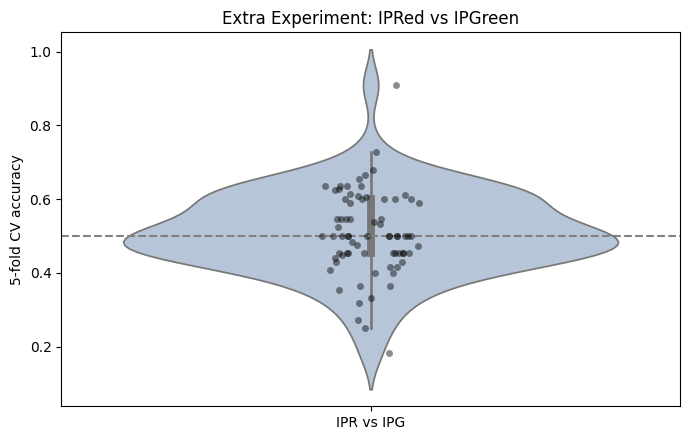

In [11]:
cache_file = paths.tables_dir / "ipr_vs_ipg_riemann.csv"


def standardize_subject_wise_quick(X_train, X_test):
    mean = X_train.mean(axis=(0, 2), keepdims=True)
    std = np.maximum(X_train.std(axis=(0, 2), keepdims=True), 1e-6)
    return (X_train - mean) / std, (X_test - mean) / std


try:
    df_ipgipr = pd.read_csv(cache_file)
except FileNotFoundError:
    rows = []
    for sub in target_subjects:
        X_sub, y_sub = X_subs_ipgipr[sub], y_subs_ipgipr[sub]
        splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)
        if not splits:
            print(f"Skipping {sub}: not enough balanced IPR/IPG trials for CV")
            continue

        for fold, (tr, te) in enumerate(splits, start=1):
            X_tr, X_te = standardize_subject_wise_quick(X_sub[tr], X_sub[te])
            pipeline = make_pipeline(
                Covariances(estimator="oas"),
                TangentSpace(metric="riemann"),
                LDA(solver="lsqr", shrinkage="auto"),
            )
            pipeline.fit(X_tr, y_sub[tr])
            y_pred = pipeline.predict(X_te)
            rows.append(
                {
                    "Task": "IPR vs IPG",
                    "Subject": sub,
                    "Fold": fold,
                    "Accuracy": accuracy_score(y_sub[te], y_pred),
                    "N_Train": len(tr),
                    "N_Test": len(te),
                    "Class_0": "IPR",
                    "Class_1": "IPG",
                }
            )

    df_ipgipr = pd.DataFrame(rows)
    df_ipgipr.to_csv(cache_file, index=False)

summary = df_ipgipr.groupby("Subject")["Accuracy"].agg(["mean", "std", "count"]).reset_index()
print("\n=== Extra Experiment: IPRed vs IPGreen (Riemann covariance + LDA) ===")
print(summary.to_string(index=False))
print(
    f"\nCohort mean accuracy: {df_ipgipr['Accuracy'].mean():.3f} +/- {df_ipgipr.groupby('Subject')['Accuracy'].mean().std():.3f}"
)

plt.figure(figsize=(7, 4.5))
sns.violinplot(data=df_ipgipr, x="Task", y="Accuracy", color="lightsteelblue", inner="box")
sns.stripplot(data=df_ipgipr, x="Task", y="Accuracy", color="black", alpha=0.45, jitter=0.08)
plt.axhline(0.5, linestyle="--", color="gray")
plt.title("Extra Experiment: IPRed vs IPGreen")
plt.ylabel("5-fold CV accuracy")
plt.xlabel("")
plt.tight_layout()
plt.savefig(paths.figures_dir / "ipr_vs_ipg_riemann_accuracy.png", dpi=300)
plt.show()

### Experiment 1: Preprocessing & Normalization Ablation

We compare normalization methods strictly fit inside temporal cross-validation folds to prevent temporal data leakage:
1. **No Normalization**: Voltage scaled to microvolts ($X \times 1e6$).
2. **Trial-wise Normalization**: Z-score calculated per trial, channel, and time axis.
3. **Global Train-Fold Normalization**: Mean/std fit on the training fold across all trials, and applied to test.
4. **Subject-level Normalization**: Mean/std fit *only* on the training trials of a subject, and applied to both train and test trials.
5. **Standard Scaler Normalization**: StandardScaler applied to 2D trial-channel-time data, fit on training fold and applied to test fold.
6. **Robust Scaler Normalization**: RobustScaler applied to 2D trial-channel-time data, fit on training fold and applied to test fold.


=== Normalization Ablation Summary (C vs IP) ===
        Normalization  Accuracy  Std Dev
        Robust Scaler  0.587722 0.075954
      Standard Scaler  0.578659 0.085694
     No Normalization  0.576778 0.076896
Global Fold Z-scoring  0.576347 0.078903
        Subject-level  0.576347 0.078903
 Trial-wise Z-scoring  0.575111 0.087356


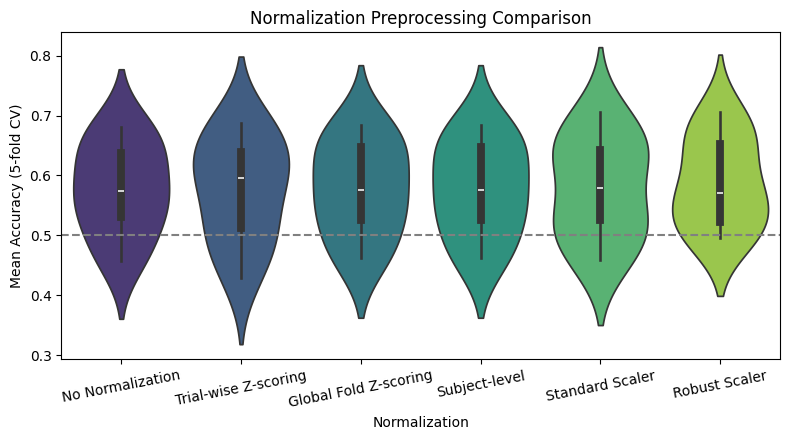

Pairwise t-test: No Normalization vs Trial-wise Z-scoring | t=0.098, p=0.924
Pairwise t-test: No Normalization vs Global Fold Z-scoring | t=0.134, p=0.896
Pairwise t-test: No Normalization vs Subject-level | t=0.134, p=0.896
Pairwise t-test: No Normalization vs Standard Scaler | t=-0.233, p=0.821
Pairwise t-test: No Normalization vs Robust Scaler | t=-1.518, p=0.163
Pairwise t-test: Trial-wise Z-scoring vs Global Fold Z-scoring | t=-0.069, p=0.947
Pairwise t-test: Trial-wise Z-scoring vs Subject-level | t=-0.069, p=0.947
Pairwise t-test: Trial-wise Z-scoring vs Standard Scaler | t=-0.205, p=0.842
Pairwise t-test: Trial-wise Z-scoring vs Robust Scaler | t=-0.714, p=0.493
Pairwise t-test: Global Fold Z-scoring vs Subject-level | t=nan, p=nan
Pairwise t-test: Global Fold Z-scoring vs Standard Scaler | t=-0.333, p=0.747
Pairwise t-test: Global Fold Z-scoring vs Robust Scaler | t=-1.554, p=0.155
Pairwise t-test: Subject-level vs Standard Scaler | t=-0.333, p=0.747
Pairwise t-test: Subject-l

In [3]:
def standardize_trial_wise(X_train, X_test):
    def _std(X):
        mean = X.mean(axis=-1, keepdims=True)
        std = X.std(axis=-1, keepdims=True)
        std = np.maximum(std, 1e-6)
        return (X - mean) / std

    return _std(X_train), _std(X_test)


def standardize_global_fold(X_train, X_test):
    mean = X_train.mean(axis=(0, 2), keepdims=True)
    std = X_train.std(axis=(0, 2), keepdims=True)
    std = np.maximum(std, 1e-6)
    return (X_train - mean) / std, (X_test - mean) / std


def standardize_subject_wise(X_train, X_test):
    mean = X_train.mean(axis=(0, 2), keepdims=True)
    std = X_train.std(axis=(0, 2), keepdims=True)
    std = np.maximum(std, 1e-6)
    return (X_train - mean) / std, (X_test - mean) / std


def standardize_robust_scaler(X_train, X_test):
    n_trials, n_channels, n_times = X_train.shape
    X_train_2d = X_train.reshape(n_trials, -1)
    X_test_2d = X_test.reshape(X_test.shape[0], -1)
    from sklearn.preprocessing import RobustScaler

    scaler = RobustScaler()
    X_train_scaled = scaler.fit_transform(X_train_2d)
    X_test_scaled = scaler.transform(X_test_2d)
    return X_train_scaled.reshape(n_trials, n_channels, n_times), X_test_scaled.reshape(
        X_test.shape[0], n_channels, n_times
    )


def standardize_standard_scaler(X_train, X_test):
    n_trials, n_channels, n_times = X_train.shape
    X_train_2d = X_train.reshape(n_trials, -1)
    X_test_2d = X_test.reshape(X_test.shape[0], -1)
    from sklearn.preprocessing import StandardScaler, RobustScaler

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_2d)
    X_test_scaled = scaler.transform(X_test_2d)
    return X_train_scaled.reshape(n_trials, n_channels, n_times), X_test_scaled.reshape(
        X_test.shape[0], n_channels, n_times
    )


def standardize_none(X_train, X_test):
    return X_train * 1e6, X_test * 1e6


cache_file = paths.tables_dir / "exp1_preprocessing_results.csv"


try:
    df_res = pd.read_csv(cache_file)
    # Aggregate results
    summary = df_res.groupby("Normalization")["Accuracy"].mean().reset_index()
    summary["Std Dev"] = df_res.groupby("Normalization")["Accuracy"].std().values
    summary = summary.sort_values("Accuracy", ascending=False)
    print("\n=== Normalization Ablation Summary (C vs IP) ===")
    print(summary.to_string(index=False))

    # Violin plot
    plt.figure(figsize=(8, 4.5))
    sns.violinplot(data=df_res, x="Normalization", y="Accuracy", palette="viridis", hue="Normalization", inner="box")
    plt.axhline(0.5, linestyle="--", color="gray", label="Chance")
    plt.title("Normalization Preprocessing Comparison")
    plt.ylabel("Mean Accuracy (5-fold CV)")
    plt.xticks(rotation=11)
    plt.tight_layout()
    plt.savefig(paths.figures_dir / "experiment1_normalization_comparison.png", dpi=300)
    plt.show()

    # pairwise t-tests
    from scipy.stats import ttest_rel

    norm_types = df_res["Normalization"].unique()
    for i in range(len(norm_types)):
        for j in range(i + 1, len(norm_types)):
            group1 = df_res[df_res["Normalization"] == norm_types[i]]["Accuracy"]
            group2 = df_res[df_res["Normalization"] == norm_types[j]]["Accuracy"]
            t_stat, p_val = ttest_rel(group1, group2)
            print(f"Pairwise t-test: {norm_types[i]} vs {norm_types[j]} | t={t_stat:.3f}, p={p_val:.3f}")

except FileNotFoundError:
    modes = {
        "No Normalization": standardize_none,
        "Trial-wise Z-scoring": standardize_trial_wise,
        "Global Fold Z-scoring": standardize_global_fold,
        "Subject-level": standardize_subject_wise,
        "Standard Scaler": standardize_standard_scaler,
        "Robust Scaler": standardize_robust_scaler,
    }

    results = []
    for sub in target_subjects:
        X_sub, y_sub = X_subs_c[sub], y_subs_c[sub]

        splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)

        for mode_name, norm_fn in modes.items():
            print(f"Processing {mode_name}...")
            accs = []
            for train_idx, test_idx in splits:
                print(f"  Split: {train_idx.shape[0]} train, {test_idx.shape[0]} test")
                X_tr, X_te = norm_fn(X_sub[train_idx], X_sub[test_idx])
                y_tr, y_te = y_sub[train_idx], y_sub[test_idx]

                pipeline = make_pipeline(
                    Covariances(estimator="oas"), TangentSpace(metric="riemann"), LDA(solver="lsqr", shrinkage="auto")
                )
                pipeline.fit(X_tr, y_tr)
                accs.append(accuracy_score(y_te, pipeline.predict(X_te)))
            results.append({"Subject": sub, "Normalization": mode_name, "Accuracy": np.mean(accs)})

    df_res = pd.DataFrame(results)
    df_res.to_csv(cache_file, index=False)

All normalization methods achieved similar results, with `Trial-wise Z-scoring` performing slightly worse. RobustScaler had the highest accuracy suggesting that outliers could be an issue in this dataset. The results indicate that the choice of normalization method does not significantly impact decoding performance, but future experiments will see if this holds true for more complex representations and classifiers.

### Experiment 2: Representation Diagnostics

We run this diagnostic on **both tasks (`c_vs_ip` and `im_vs_ip`)** using the locked Riemannian classifier to determine where the information is located before spending days training deep neural network backbones.

We evaluate three scopes of representation:
1. **Spatial scope**:
   - *Paper ROI channels*: P7, P8, PO7, PO3, POz, PO4, PO8, O1, Oz, O2 for alpha; Fz, FCz, Cz for theta (13 channels).
   - *Temporal cluster channels*: Frontomedial cluster channels (9 channels).
   - *Parieto-occipital cluster channels*: Parieto-occipital cluster channels (13 channels).
   - *Cluster channels*: Parieto-occipital + frontomedial cluster channels (22 channels).
   - *29 channels*: Expanded clustering layout.
   - *60 channels*: Agnostic/all channels.
2. **Time scope**:
   - *First 500ms*: 0.0s to 0.5s.
   - *Middle 500ms*: 0.5s to 1.0s.
   - *Last 500ms*: 1.0s to 1.5s.
   - *Conflict window*: plotted under one shared `Conflict Window` label; C vs IP uses 0.375s to 1.242s, and IM vs IP uses 0.258s to 1.242s.
   - *Full epoch*: 0.0s to 1.5s.
3. **Spectral scope**:
   - *Theta* (5-7 Hz)
   - *Alpha* (8-12 Hz)
   - *Theta+Alpha* (5-12 Hz)
   - *Broadband* (1-40 Hz)

The IM-vs-IP conflict-window update is patched into the cached CSV separately, without recalculating the spatial or spectral diagnostics; both tasks keep the same `Config` label for clean violin plots.



=== Spatial Diagnostics Summary ===
                        Config     Task     mean      std
             All Channels (60) IM vs IP 0.535271 0.065183
Parieto-Occipital Cluster (13) IM vs IP 0.535209 0.070951
         Cluster channels (22) IM vs IP 0.532245 0.058647
          Temporal Cluster (9) IM vs IP 0.511819 0.035322
                Paper ROI (13) IM vs IP 0.500423 0.067027
             All Channels (60)  C vs IP 0.568376 0.066453
Parieto-Occipital Cluster (13)  C vs IP 0.557458 0.043068
         Cluster channels (22)  C vs IP 0.551695 0.058609
                Paper ROI (13)  C vs IP 0.549965 0.026845
          Temporal Cluster (9)  C vs IP 0.519965 0.053478


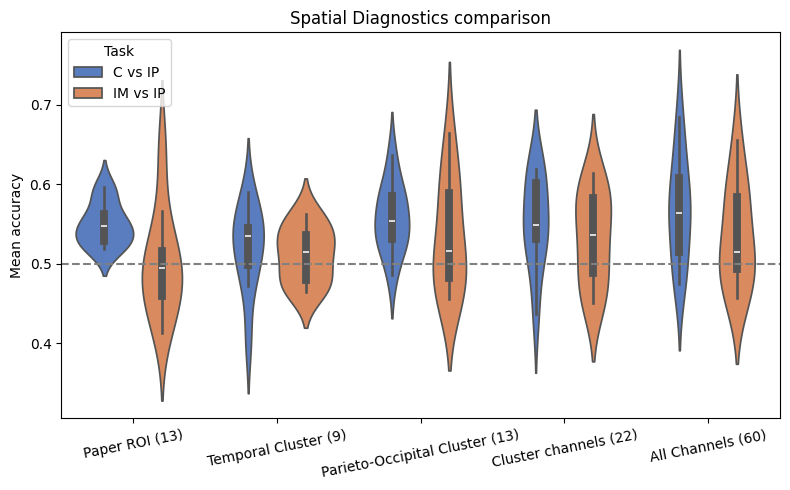


=== Temporal Diagnostics Summary ===
                       Config     Task     mean      std
     Second window (0.5-1.0s) IM vs IP 0.571176 0.048002
Conflict Window (~0.3-1.242s) IM vs IP 0.566554 0.074720
        Full Epoch (0.0-1.5s) IM vs IP 0.535271 0.065183
      First window (0.0-0.5s) IM vs IP 0.508690 0.050306
      Third window (1.0-1.5s) IM vs IP 0.507621 0.071726
Conflict Window (~0.3-1.242s)  C vs IP 0.576347 0.078903
     Second window (0.5-1.0s)  C vs IP 0.572307 0.065261
        Full Epoch (0.0-1.5s)  C vs IP 0.568376 0.066453
      Third window (1.0-1.5s)  C vs IP 0.563025 0.048115
      First window (0.0-0.5s)  C vs IP 0.480008 0.031979


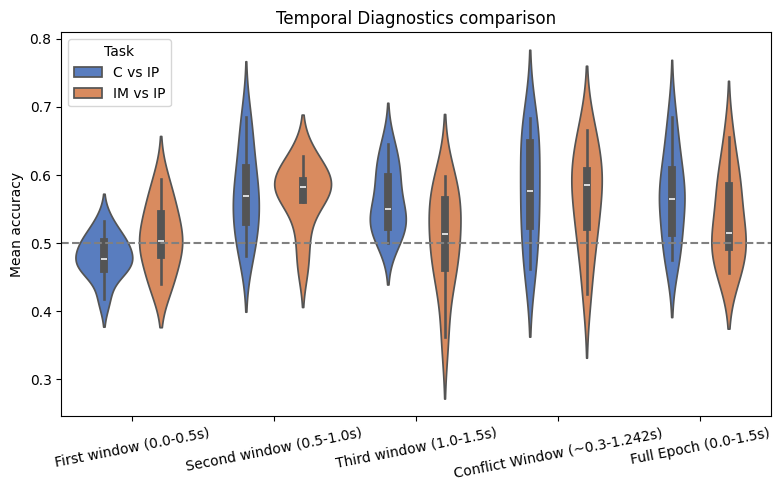


=== Spectral Diagnostics Summary ===
               Config     Task     mean      std
  Broadband (1-40 Hz) IM vs IP 0.562350 0.034283
       Theta (5-7 Hz) IM vs IP 0.518896 0.076483
Theta+Alpha (5-12 Hz) IM vs IP 0.514469 0.067511
      Alpha (8-12 Hz) IM vs IP 0.500692 0.048257
Theta+Alpha (5-12 Hz)  C vs IP 0.574311 0.059049
  Broadband (1-40 Hz)  C vs IP 0.565614 0.089113
      Alpha (8-12 Hz)  C vs IP 0.553748 0.060202
       Theta (5-7 Hz)  C vs IP 0.538075 0.031346


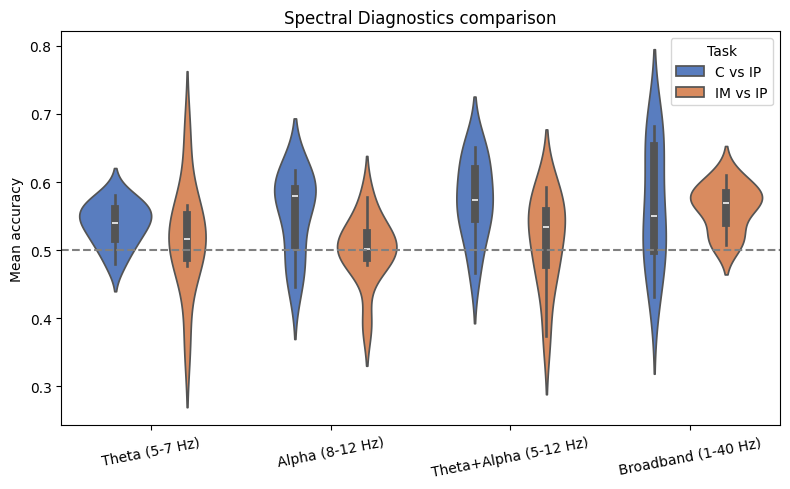

In [4]:
from mne.filter import filter_data

cache_file = paths.cache_dir / "exp2_diagnostics.csv"
CONFLICT_WINDOWS = {"C vs IP": (0.375, 1.242), "IM vs IP": (0.258, 1.242)}

try:
    df_diag = pd.read_csv(cache_file)
    # Render comparative plots side by side
    for dim in ["Spatial", "Temporal", "Spectral"]:
        print(f"\n=== {dim} Diagnostics Summary ===")
        dim_summary = (
            df_diag[df_diag["Dimension"] == dim]
            .groupby(["Config", "Task"])["Accuracy"]
            .agg(["mean", "std"])
            .reset_index()
        )
        dim_summary = dim_summary.sort_values(["Task", "mean"], ascending=False)
        print(dim_summary.to_string(index=False))

        plt.figure(figsize=(8, 5))
        sns.violinplot(data=df_diag[df_diag["Dimension"] == dim], x="Config", y="Accuracy", hue="Task", palette="muted")
        plt.axhline(0.5, linestyle="--", color="gray")
        plt.title(f"{dim} Diagnostics comparison")
        plt.xticks(rotation=11)
        plt.xlabel("")
        plt.ylabel("Mean accuracy")
        plt.tight_layout()
        plt.savefig(paths.figures_dir / f"experiment2_{dim.lower()}_diagnostics.png", dpi=300)
        plt.show()
except FileNotFoundError:
    roi_chans = ["P7", "P8", "PO7", "PO3", "POz", "PO4", "PO8", "O1", "Oz", "O2", "Fz", "FCz", "Cz"]
    cluster_chans = TARGET_BANDS_CLUSTERS["theta"] + TARGET_BANDS_CLUSTERS["alpha"]

    tasks_dict = {
        "C vs IP": (X_subs_c, y_subs_c, dataset_c),
        "IM vs IP": (X_subs_im, y_subs_im, dataset_im),
    }

    all_diagnostics = []
    sfreq = 128.0

    for task_lbl, (X_dict, y_dict, ds) in tasks_dict.items():
        for sub in target_subjects:
            print(f"Processing diagnostics for Task: {task_lbl}, Subject: {sub}")
            X_sub, y_sub = X_dict[sub], y_dict[sub]

            # 1. Spatial Scope Ablation
            spatial_configs = {
                "Paper ROI (13)": [ch for ch in roi_chans if ch in ds.channel_names],
                "Temporal Cluster (9)": [ch for ch in TARGET_BANDS_CLUSTERS["theta"] if ch in ds.channel_names],
                "Parieto-Occipital Cluster (13)": [
                    ch for ch in TARGET_BANDS_CLUSTERS["alpha"] if ch in ds.channel_names
                ],
                "Cluster channels (22)": [ch for ch in cluster_chans if ch in ds.channel_names],
                "All Channels (60)": ds.channel_names,
            }
            for spat_name, picks in spatial_configs.items():
                picks_idx = [ds.channel_names.index(ch) for ch in picks]
                # standard Z-scoring, Riemann
                X_crop = X_sub[:, picks_idx]

                splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)
                accs = []
                for tr, te in splits:
                    X_tr, X_te = standardize_subject_wise(X_crop[tr], X_crop[te])
                    pipeline = make_pipeline(
                        Covariances(estimator="oas"),
                        TangentSpace(metric="riemann"),
                        LDA(solver="lsqr", shrinkage="auto"),
                    )
                    pipeline.fit(X_tr, y_sub[tr])
                    accs.append(accuracy_score(y_sub[te], pipeline.predict(X_te)))
                all_diagnostics.append(
                    {
                        "Task": task_lbl,
                        "Dimension": "Spatial",
                        "Config": spat_name,
                        "Accuracy": np.mean(accs),
                        "Std Dev": np.std(accs),
                    }
                )

            # 2. Time Scope Ablation
            conflict_start, conflict_stop = CONFLICT_WINDOWS[task_lbl]
            time_configs = {
                "First window (0.0-0.5s)": (ds.times >= 0.0) & (ds.times <= 0.5),
                "Second window (0.5-1.0s)": (ds.times > 0.5) & (ds.times <= 1.0),
                "Third window (1.0-1.5s)": (ds.times > 1.0) & (ds.times <= 1.5),
                "Conflict Window": (ds.times >= conflict_start) & (ds.times <= conflict_stop),
                "Full Epoch (0.0-1.5s)": (ds.times >= 0.0) & (ds.times <= 1.5),
            }
            for time_name, t_mask in time_configs.items():
                X_crop = X_sub[..., t_mask]
                splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)
                accs = []
                for tr, te in splits:
                    X_tr, X_te = standardize_subject_wise(X_crop[tr], X_crop[te])
                    pipeline = make_pipeline(
                        Covariances(estimator="oas"),
                        TangentSpace(metric="riemann"),
                        LDA(solver="lsqr", shrinkage="auto"),
                    )
                    pipeline.fit(X_tr, y_sub[tr])
                    accs.append(accuracy_score(y_sub[te], pipeline.predict(X_te)))
                all_diagnostics.append(
                    {
                        "Task": task_lbl,
                        "Dimension": "Temporal",
                        "Config": time_name,
                        "Accuracy": np.mean(accs),
                        "Std Dev": np.std(accs),
                    }
                )

            # 3. Spectral Scope Ablation
            spectral_configs = {
                "Theta (5-7 Hz)": (5.0, 7.0),
                "Alpha (8-12 Hz)": (8.0, 12.0),
                "Theta+Alpha (5-12 Hz)": (5.0, 12.0),
                "Broadband (1-40 Hz)": (1.0, 40.0),
            }
            # Keep spectral diagnostics unchanged from the original experiment.
            t_mask = (ds.times >= 0.375) & (ds.times <= 1.242)
            for spec_name, (l_freq, h_freq) in spectral_configs.items():
                X_filt = filter_data(
                    X_sub[..., t_mask].astype(np.float64),
                    sfreq=sfreq,
                    l_freq=l_freq,
                    h_freq=h_freq,
                    method="iir",
                    verbose=False,
                )
                splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)
                accs = []
                for tr, te in splits:
                    X_tr, X_te = standardize_subject_wise(X_filt[tr], X_filt[te])
                    pipeline = make_pipeline(
                        Covariances(estimator="oas"),
                        TangentSpace(metric="riemann"),
                        LDA(solver="lsqr", shrinkage="auto"),
                    )
                    pipeline.fit(X_tr, y_sub[tr])
                    accs.append(accuracy_score(y_sub[te], pipeline.predict(X_te)))
                all_diagnostics.append(
                    {
                        "Task": task_lbl,
                        "Dimension": "Spectral",
                        "Config": spec_name,
                        "Accuracy": np.mean(accs),
                        "Std Dev": np.std(accs),
                    }
                )

    df_diag = pd.DataFrame(all_diagnostics)
    df_diag.to_csv(cache_file, index=False)

### Experiment 3: Classical Machine Learning Branch (LR, LDA, RF, XGB, LGBM)

Using fold-wise Hilbert average envelope amplitudes from the representation choices suggested by Experiments 1-2, we compare five classical models for **both** tasks. The feature recipe is task-specific but fixed before model comparison: C vs IP uses the theta+alpha conflict-window cluster because it was strongest in the previous diagnostics, while IM vs IP uses broadband features in the second window over all channels because those were strongest for that task.



=== Classical Machine Learning Comparison ===
    Task                   Classifier     mean      std  count
 C vs IP          Logistic Regression 0.566194 0.094773     50
 C vs IP Linear Discriminant Analysis 0.552381 0.089797     50
 C vs IP                      XGBoost 0.535705 0.090438     50
 C vs IP                Random Forest 0.532697 0.094762     50
 C vs IP                     LightGBM 0.512623 0.103223     50
IM vs IP          Logistic Regression 0.516120 0.088925     50
IM vs IP Linear Discriminant Analysis 0.505831 0.119269     50
IM vs IP                     LightGBM 0.503436 0.098212     50
IM vs IP                      XGBoost 0.501512 0.092444     50
IM vs IP                Random Forest 0.497605 0.103525     50


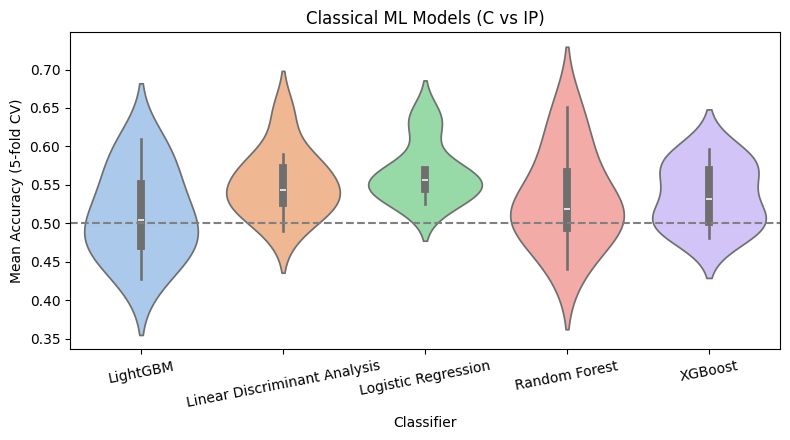

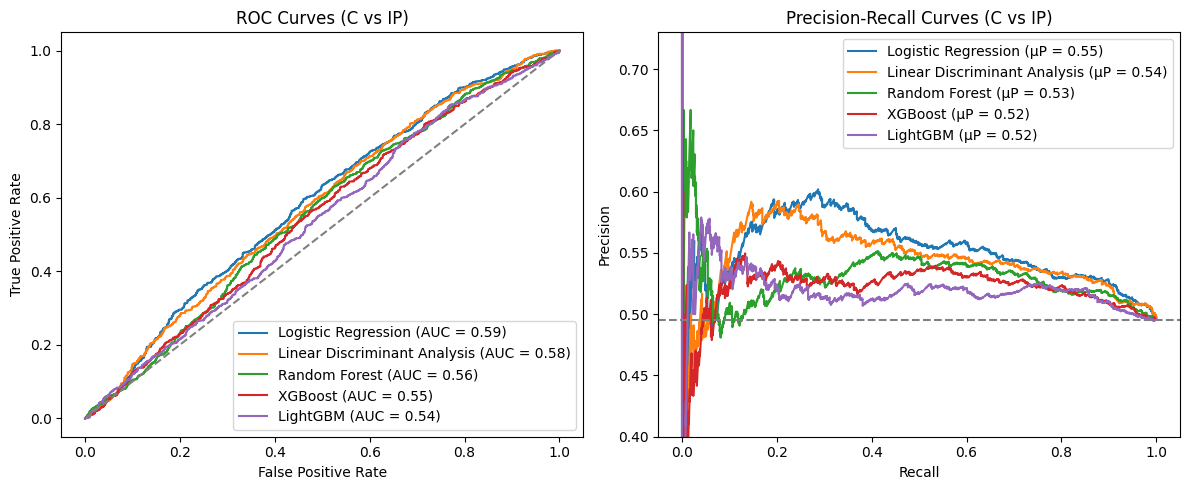

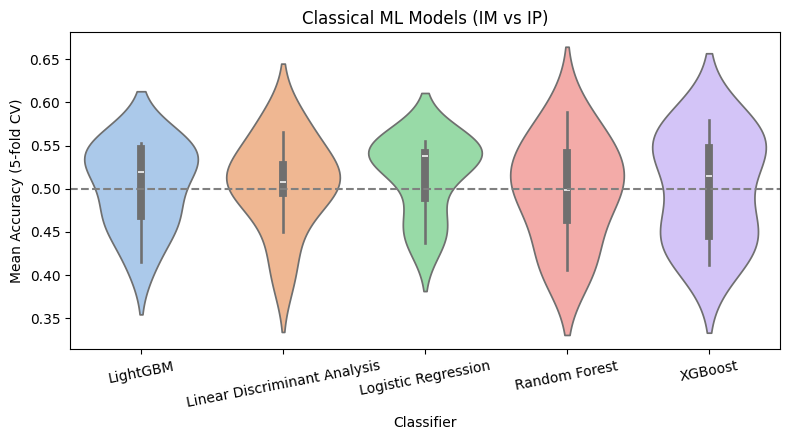

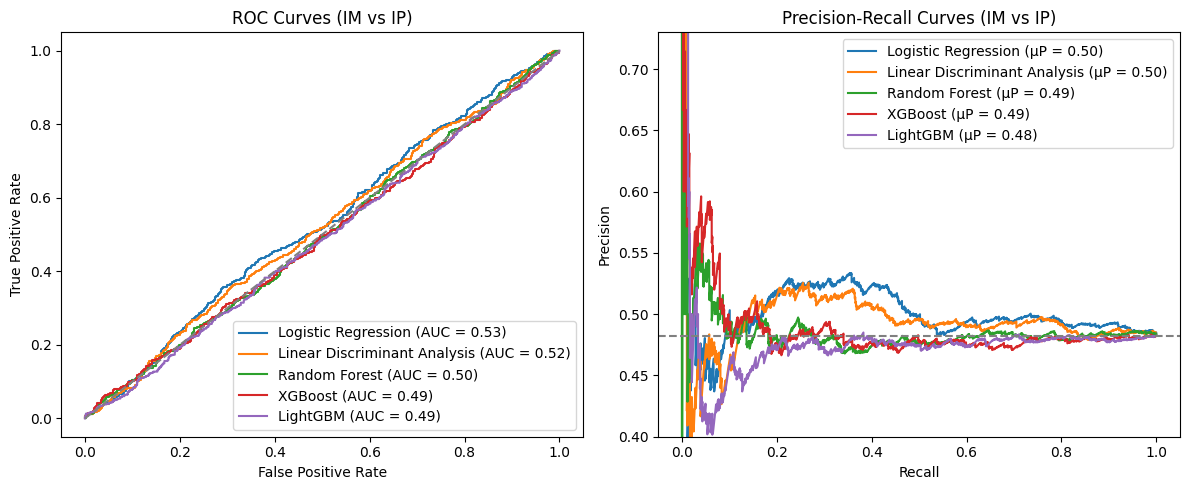

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

cache_file = paths.tables_dir / "exp3_classical_ml_results.csv"


def extract_exp3_features(X_sub, ds, *, channel_mode, time_window, bandpass):
    if channel_mode == "all":
        ch_idx = list(range(len(ds.channel_names)))
    elif channel_mode == "cluster":
        cluster_chans = TARGET_BANDS_CLUSTERS["theta"] + TARGET_BANDS_CLUSTERS["alpha"]
        ch_idx = [ds.channel_names.index(ch) for ch in cluster_chans if ch in ds.channel_names]
    elif channel_mode == "parieto_occipital":
        ch_idx = [ds.channel_names.index(ch) for ch in TARGET_BANDS_CLUSTERS["alpha"] if ch in ds.channel_names]
    else:
        raise ValueError(f"Unknown channel_mode: {channel_mode}")

    t_mask = (ds.times >= time_window[0]) & (ds.times <= time_window[1])
    X_sel = X_sub[:, ch_idx, :]
    if bandpass is not None:
        X_sel = filter_data(
            X_sel.astype(np.float64),
            sfreq=128.0,
            l_freq=bandpass[0],
            h_freq=bandpass[1],
            method="iir",
            verbose=False,
        )
    envelopes = np.abs(hilbert(X_sel[..., t_mask], axis=-1))
    return envelopes.mean(axis=-1)


try:
    df_ml = pd.read_csv(cache_file)
    if "Task" not in df_ml.columns:
        df_ml["Task"] = "C vs IP"

    fold_summary = df_ml.groupby(["Task", "Classifier", "Subject", "Fold"])["Fold_Accuracy"].first().reset_index()
    summary_mean = (
        fold_summary.groupby(["Task", "Classifier"])["Fold_Accuracy"]
        .agg(["mean", "std", "count"])
        .reset_index()
        .sort_values(["Task", "mean"], ascending=[True, False])
    )

    print("\n=== Classical Machine Learning Comparison ===")
    print(summary_mean.to_string(index=False))

    for task_lbl in ["C vs IP", "IM vs IP"]:
        d_fold = fold_summary[fold_summary["Task"] == task_lbl]
        d_trials = df_ml[df_ml["Task"] == task_lbl]
        if d_fold.empty or d_trials.empty:
            continue

        plt.figure(figsize=(8, 4.5))
        df_violin = d_fold.groupby(["Classifier", "Subject"])["Fold_Accuracy"].mean().reset_index()
        sns.violinplot(data=df_violin, x="Classifier", y="Fold_Accuracy", palette="pastel", hue="Classifier")
        plt.axhline(0.5, linestyle="--", color="gray")
        plt.title(f"Classical ML Models ({task_lbl})")
        plt.ylabel("Mean Accuracy (5-fold CV)")
        plt.xticks(rotation=11)
        plt.tight_layout()
        tag = "c_vs_ip" if task_lbl == "C vs IP" else "im_vs_ip"
        plt.savefig(paths.figures_dir / f"experiment3_classical_ml_comparison_{tag}.png", dpi=300)
        plt.show()

        fig, axes = plt.subplots(1, 2, figsize=(12, 5))
        for name in d_trials["Classifier"].unique():
            df_clf = d_trials[d_trials["Classifier"] == name]
            y_true = df_clf["True_Label"].values
            y_scores = df_clf["Probability"].values
            fpr, tpr, _ = roc_curve(y_true, y_scores)
            precision, recall, _ = precision_recall_curve(y_true, y_scores)
            axes[0].plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.2f})")
            axes[1].plot(recall, precision, label=f"{name} (μP = {average_precision_score(y_true, y_scores):.2f})")

        axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
        axes[0].set_title(f"ROC Curves ({task_lbl})")
        axes[0].set_xlabel("False Positive Rate")
        axes[0].set_ylabel("True Positive Rate")
        axes[0].legend()

        axes[1].axhline(d_trials["True_Label"].mean(), linestyle="--", color="gray")
        axes[1].set_title(f"Precision-Recall Curves ({task_lbl})")
        axes[1].set_xlabel("Recall")
        axes[1].set_ylabel("Precision")
        axes[1].set_ylim([0.4, 0.73])
        axes[1].legend()

        plt.tight_layout()
        plt.savefig(paths.figures_dir / f"experiment3_classical_ml_roc_pr_curves_{tag}.png", dpi=300)
        plt.show()

except FileNotFoundError:
    model_factories = {
        "Logistic Regression": lambda: LogisticRegression(
            C=1.0, penalty="l2", class_weight="balanced", random_state=42
        ),
        "Linear Discriminant Analysis": lambda: LDA(solver="lsqr", shrinkage="auto"),
        "Random Forest": lambda: RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42),
        "XGBoost": lambda: XGBClassifier(
            n_estimators=50, max_depth=3, learning_rate=0.1, random_state=42, eval_metric="logloss"
        ),
        "LightGBM": lambda: LGBMClassifier(
            n_estimators=50, max_depth=3, learning_rate=0.1, random_state=42, verbose=-1
        ),
    }

    task_feature_configs = {
        "C vs IP": {
            "data": (X_subs_c, y_subs_c, dataset_c),
            "channel_mode": "cluster",
            "time_window": (0.375, 1.242),
            "bandpass": (5.0, 12.0),
            "feature_label": "Cluster theta+alpha envelope, conflict window",
        },
        "IM vs IP": {
            "data": (X_subs_im, y_subs_im, dataset_im),
            "channel_mode": "all",
            "time_window": (0.5, 1.0),
            "bandpass": (1.0, 40.0),
            "feature_label": "All-channel broadband envelope, second window",
        },
    }

    ml_results = []

    for task_lbl, cfg in task_feature_configs.items():
        X_dict, y_dict, ds = cfg["data"]
        print(f"\nRunning Experiment 3 model comparison for {task_lbl}: {cfg['feature_label']}")
        for sub in target_subjects:
            X_sub, y_sub = X_dict[sub], y_dict[sub]
            X_feats = extract_exp3_features(
                X_sub,
                ds,
                channel_mode=cfg["channel_mode"],
                time_window=cfg["time_window"],
                bandpass=cfg["bandpass"],
            )
            splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)

            for name, make_clf in model_factories.items():
                for fold_idx, (tr, te) in enumerate(splits, start=1):
                    clf = make_clf()
                    pipeline = make_pipeline(StandardScaler(), clf)
                    pipeline.fit(X_feats[tr], y_sub[tr])
                    y_true = y_sub[te]
                    y_pred = pipeline.predict(X_feats[te])
                    if hasattr(pipeline, "predict_proba"):
                        y_probs = pipeline.predict_proba(X_feats[te])[:, 1]
                    else:
                        scores = pipeline.decision_function(X_feats[te])
                        y_probs = 1.0 / (1.0 + np.exp(-scores))
                    acc = accuracy_score(y_true, y_pred)

                    for idx in range(len(y_true)):
                        ml_results.append(
                            {
                                "Task": task_lbl,
                                "Subject": sub,
                                "Classifier": name,
                                "Fold": fold_idx,
                                "True_Label": int(y_true[idx]),
                                "Probability": float(y_probs[idx]),
                                "Fold_Accuracy": acc,
                                "Feature_Set": cfg["feature_label"],
                            }
                        )

    df_ml = pd.DataFrame(ml_results)
    df_ml.to_csv(cache_file, index=False)

### Experiment 4: Classical Spatial Baselines (CSP, FBCSP, Riemann)

Spatial filter baselines learn combinations of signals that optimize condition variance. We compare:
1. **Broadband CSP + LDA**
2. **Filter Bank CSP (FBCSP) + LDA** (extracting spatial filters in parallel over Theta, Alpha, and Beta)
3. **Riemannian Covariance**: oasis-estimation covariance matrices projected onto Tangent space and classified by shrinkage LDA.


=== Spatial Baselines comparison (C vs IP) ===
                   Model  Accuracy
Riemann Covariance + LDA  0.576778
             FBCSP + LDA  0.564694
     Broadband CSP + LDA  0.560416


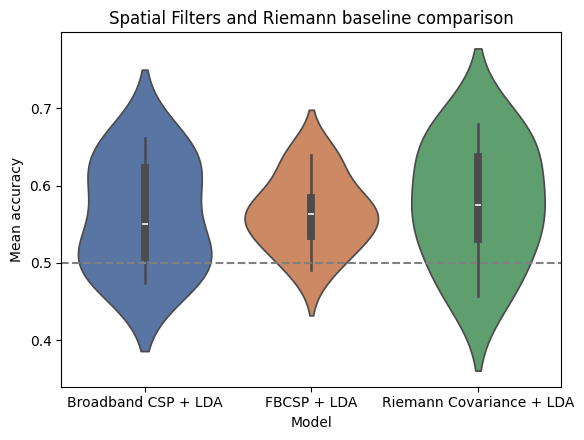

In [6]:
from mne.decoding import CSP

cache_file = paths.tables_dir / "exp4_spatial_baselines.csv"

try:
    df_spat = pd.read_csv(cache_file)
    summary = df_spat.groupby("Model")["Accuracy"].mean().reset_index().sort_values("Accuracy", ascending=False)
    print("\n=== Spatial Baselines comparison (C vs IP) ===")
    print(summary.to_string(index=False))

    plt.figure(figsize=(6, 4.5))
    sns.violinplot(data=df_spat, x="Model", y="Accuracy", palette="deep", hue="Model")
    plt.axhline(0.5, linestyle="--", color="gray")
    plt.title("Spatial Filters and Riemann baseline comparison")
    plt.ylabel("Mean accuracy")
    plt.tight_layout()
    plt.savefig(paths.figures_dir / "experiment4_spatial_baselines_comparison.png", dpi=300)
    plt.show()
except FileNotFoundError:
    spatial_results = []

    for sub in target_subjects:
        X_sub, y_sub = X_subs_c[sub], y_subs_c[sub]
        t_mask = (dataset_c.times >= 0.375) & (dataset_c.times <= 1.242)
        X_crop = X_sub[..., t_mask] * 1e6

        splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)

        # 1. Broadband CSP
        accs_csp = []
        for tr, te in splits:
            csp = CSP(n_components=4, reg="ledoit_wolf", log=True, cov_est="epoch")
            clf = LDA(solver="lsqr", shrinkage="auto")
            X_tr = csp.fit_transform(X_crop[tr].astype(np.float64), y_sub[tr])
            X_te = csp.transform(X_crop[te].astype(np.float64))
            clf.fit(X_tr, y_sub[tr])
            accs_csp.append(accuracy_score(y_sub[te], clf.predict(X_te)))
        spatial_results.append({"Subject": sub, "Model": "Broadband CSP + LDA", "Accuracy": np.mean(accs_csp)})

        # 2. Filter Bank CSP (Theta, Alpha, Beta)
        fbands = {"Theta": (4.0, 8.0), "Alpha": (8.0, 12.0), "Beta": (12.0, 30.0)}
        X_filt_bands = {}
        for bname, (lf, hf) in fbands.items():
            X_filt_bands[bname] = filter_data(
                X_crop.astype(np.float64), sfreq=128.0, l_freq=lf, h_freq=hf, method="iir", verbose=False
            )

        accs_fbcsp = []
        for tr, te in splits:
            tr_feats, te_feats = [], []
            for bname in fbands:
                csp = CSP(n_components=4, reg="ledoit_wolf", log=True, cov_est="epoch")
                tr_feats.append(csp.fit_transform(X_filt_bands[bname][tr], y_sub[tr]))
                te_feats.append(csp.transform(X_filt_bands[bname][te]))
            X_tr_fb = np.concatenate(tr_feats, axis=1)
            X_te_fb = np.concatenate(te_feats, axis=1)
            clf = LDA(solver="lsqr", shrinkage="auto")
            clf.fit(X_tr_fb, y_sub[tr])
            accs_fbcsp.append(accuracy_score(y_sub[te], clf.predict(X_te_fb)))
        spatial_results.append({"Subject": sub, "Model": "FBCSP + LDA", "Accuracy": np.mean(accs_fbcsp)})

        # 3. Riemann Baseline
        accs_riemann = []
        for tr, te in splits:
            pipeline = make_pipeline(
                Covariances(estimator="oas"), TangentSpace(metric="riemann"), LDA(solver="lsqr", shrinkage="auto")
            )
            pipeline.fit(X_crop[tr], y_sub[tr])
            accs_riemann.append(accuracy_score(y_sub[te], pipeline.predict(X_crop[te])))
        spatial_results.append({"Subject": sub, "Model": "Riemann Covariance + LDA", "Accuracy": np.mean(accs_riemann)})

    df_spat = pd.DataFrame(spatial_results)
    df_spat.to_csv(cache_file, index=False)

### Experiment 5: Connectivity & Network Structure Representations

Because Binocular Rivalry is hypothesized to involve frontomedial and parieto-occipital interactions, we calculate **trial-wise Phase Locking Value (PLV)** connectivity matrices in the Theta and Alpha bands for both tasks. PLV matrices are treated as connectivity features rather than covariance matrices: we vectorize the upper triangle, standardize features inside each training fold, and classify with LDA. Results are stored at fold level and summarized with text-only tests against chance.



=== Connectivity Classification Results ===
    Task Connectivity     mean      std  count
 C vs IP    Alpha PLV 0.503705 0.046581     10
 C vs IP    Theta PLV 0.511866 0.049336     10
IM vs IP    Alpha PLV 0.503015 0.039232     10
IM vs IP    Theta PLV 0.472513 0.054607     10

=== Text-only statistical tests vs chance (0.5) ===
C vs IP | Alpha PLV: mean=0.504, sd=0.047, n_folds=10, one-sample t-test p=0.4035, Wilcoxon p=0.3477
C vs IP | Theta PLV: mean=0.512, sd=0.049, n_folds=10, one-sample t-test p=0.2332, Wilcoxon p=0.3125
IM vs IP | Alpha PLV: mean=0.503, sd=0.039, n_folds=10, one-sample t-test p=0.4067, Wilcoxon p=0.4229
IM vs IP | Theta PLV: mean=0.473, sd=0.055, n_folds=10, one-sample t-test p=0.9270, Wilcoxon p=0.9199


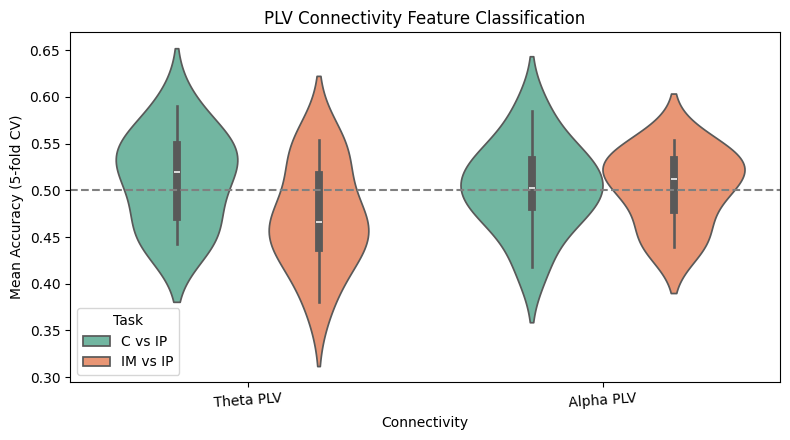

In [7]:
def compute_trial_wise_plv(X_epoch):
    # X_epoch shape: (trials, channels, times)
    z = hilbert(X_epoch, axis=-1)
    phase = np.angle(z)
    exp_phase = np.exp(1j * phase)
    times = X_epoch.shape[-1]
    plv = np.abs(np.matmul(exp_phase, exp_phase.conj().transpose(0, 2, 1))) / times
    return plv


def vectorize_connectivity_upper_triangle(plv_tensors):
    tri = np.triu_indices(plv_tensors.shape[-1], k=1)
    return plv_tensors[:, tri[0], tri[1]].astype(np.float64)


def print_chance_test_summary(df, *, value_col="Accuracy", group_cols=("Task", "Connectivity")):
    from scipy.stats import ttest_1samp, wilcoxon

    print("\n=== Text-only statistical tests vs chance (0.5) ===")
    for keys, d in df.groupby(list(group_cols)):
        vals = d[value_col].dropna().to_numpy(dtype=float)
        if vals.size == 0:
            continue
        t_stat, t_p = ttest_1samp(vals, 0.5, alternative="greater")
        try:
            w_stat, w_p = wilcoxon(vals - 0.5, alternative="greater", zero_method="wilcox")
        except ValueError:
            w_stat, w_p = np.nan, np.nan
        key_txt = " | ".join(map(str, keys if isinstance(keys, tuple) else (keys,)))
        print(
            f"{key_txt}: mean={vals.mean():.3f}, sd={vals.std(ddof=1):.3f}, "
            f"n_folds={vals.size}, one-sample t-test p={t_p:.4f}, Wilcoxon p={w_p:.4f}"
        )


cache_file = paths.tables_dir / "exp5_connectivity_results.csv"

try:
    df_conn = pd.read_csv(cache_file)
    summary = df_conn.groupby(["Task", "Connectivity"])["Accuracy"].agg(["mean", "std", "count"]).reset_index()
    print("\n=== Connectivity Classification Results ===")
    print(summary.to_string(index=False))
    print_chance_test_summary(df_conn)

    plt.figure(figsize=(8, 4.5))
    sns.violinplot(data=df_conn, x="Connectivity", y="Accuracy", palette="Set2", hue="Task", inner="box")
    plt.axhline(0.5, linestyle="--", color="gray")
    plt.title("PLV Connectivity Feature Classification")
    plt.ylabel("Mean Accuracy (5-fold CV)")
    plt.xticks(rotation=4)
    plt.tight_layout()
    plt.savefig(paths.figures_dir / "experiment5_connectivity_comparison.png", dpi=300)
    plt.show()
except FileNotFoundError:
    conn_results = []

    for task_lbl, (X_dict, y_dict, ds) in tasks_dict.items():
        print(f"\nComputing upper-triangle PLV connectivity features for: {task_lbl}")

        for sub in target_subjects:
            X_sub, y_sub = X_dict[sub], y_dict[sub]
            ch_idx = [ds.channel_names.index(ch) for ch in cluster_chans if ch in ds.channel_names]
            X_conn = X_sub[:, ch_idx, :]

            # Filter the full epoch before Hilbert/PLV to avoid crop-edge artifacts.
            X_theta = filter_data(
                X_conn.astype(np.float64), sfreq=128.0, l_freq=5.0, h_freq=7.0, method="iir", verbose=False
            )
            X_alpha = filter_data(
                X_conn.astype(np.float64), sfreq=128.0, l_freq=8.0, h_freq=12.0, method="iir", verbose=False
            )
            features_by_band = {
                "Theta PLV upper-triangle": vectorize_connectivity_upper_triangle(compute_trial_wise_plv(X_theta)),
                "Alpha PLV upper-triangle": vectorize_connectivity_upper_triangle(compute_trial_wise_plv(X_alpha)),
            }

            splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)

            for name, X_feats in features_by_band.items():
                for fold_idx, (tr, te) in enumerate(splits, start=1):
                    pipeline = make_pipeline(StandardScaler(), LDA(solver="lsqr", shrinkage="auto"))
                    pipeline.fit(X_feats[tr], y_sub[tr])
                    y_pred = pipeline.predict(X_feats[te])
                    acc = accuracy_score(y_sub[te], y_pred)
                    conn_results.append(
                        {
                            "Task": task_lbl,
                            "Subject": sub,
                            "Connectivity": name,
                            "Fold": fold_idx,
                            "Accuracy": acc,
                        }
                    )

    df_conn = pd.DataFrame(conn_results)
    df_conn.to_csv(cache_file, index=False)

### Experiment 6: Focused Deep Learning Branch

1. **EEGNet representation ablation**: We keep a compact, deterministic ablation over channel scope, time crop, and normalization so the result remains interpretable and reproducible.
2. **ST-GNN topology ablation**: Optuna is intentionally not used here. The scientific question is which graph prior is more robust, so we compare fixed topologies under the same training budget: physical electrode distance, train-fold functional PLV, identity/no-edge control, and a dense mean-field graph. The functional graph is fit only on each training fold to avoid temporal leakage.



=== Experiment 6 Deep Learning Summary ===
    Task Family                               Variant     mean      std
 C vs IP EEGNet EEGNet | all channels conflict window 0.526530 0.068677
 C vs IP EEGNet    EEGNet | clustered conflict window 0.533571 0.073856
 C vs IP EEGNet         EEGNet | clustered full epoch 0.566225 0.060712
 C vs IP EEGNet   EEGNet | clustered no normalization 0.533986 0.081345
 C vs IP ST-GNN          ST-GNN | dense graph control 0.532791 0.071557
 C vs IP ST-GNN               ST-GNN | distance graph 0.508338 0.103252
 C vs IP ST-GNN       ST-GNN | identity graph control 0.517665 0.092306
 C vs IP ST-GNN         ST-GNN | train-fold PLV graph 0.527573 0.096543
IM vs IP EEGNet EEGNet | all channels conflict window 0.528112 0.075354
IM vs IP EEGNet    EEGNet | clustered conflict window 0.515738 0.057214
IM vs IP EEGNet         EEGNet | clustered full epoch 0.503086 0.055939
IM vs IP EEGNet   EEGNet | clustered no normalization 0.533620 0.053310
IM vs IP ST-GNN     

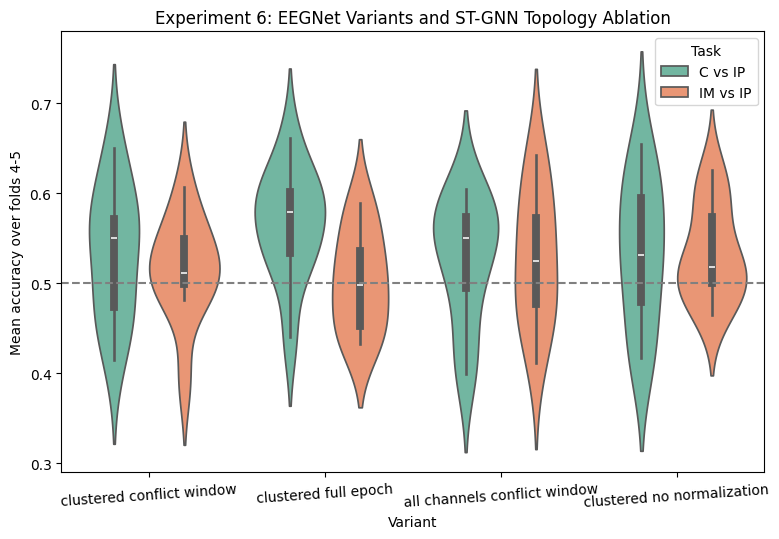

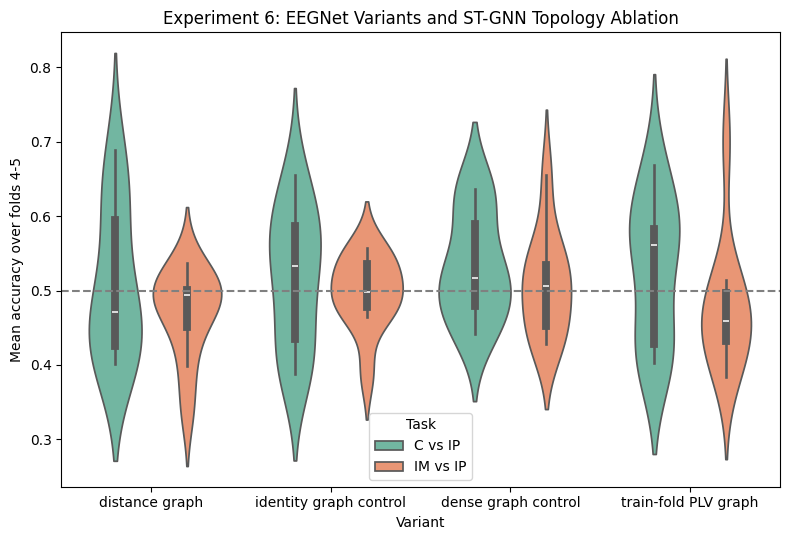

In [8]:
cache_file = paths.tables_dir / "exp6_deep_learning_results.csv"

try:
    df_dl = pd.read_csv(cache_file)
    summary = df_dl.groupby(["Task", "Family", "Variant"])["Accuracy"].agg(["mean", "std"]).reset_index()
    df_dl_eegnet = df_dl[df_dl["Family"] == "EEGNet"].copy()
    df_dl_eegnet["Variant"] = df_dl_eegnet["Variant"].str.replace("EEGNet | ", "")
    df_dl_stgnn = df_dl[df_dl["Family"] == "ST-GNN"].copy()
    df_dl_stgnn["Variant"] = df_dl_stgnn["Variant"].str.replace("ST-GNN | ", "")
    print("\n=== Experiment 6 Deep Learning Summary ===")
    print(summary.to_string(index=False))

    # EEGNet variants violin plot
    plt.figure(figsize=(8, 5.5))
    sns.violinplot(data=df_dl_eegnet, x="Variant", y="Accuracy", hue="Task", palette="Set2")
    plt.axhline(0.5, linestyle="--", color="gray")
    plt.title("Experiment 6: EEGNet Variants and ST-GNN Topology Ablation")
    plt.ylabel("Mean accuracy over folds 4-5")
    plt.xticks(rotation=4)
    plt.tight_layout()
    plt.savefig(paths.figures_dir / "experiment6_eegnet_variants_comparison.png", dpi=300)
    plt.show()

    # ST-GNN topology violin plot
    plt.figure(figsize=(8, 5.5))
    sns.violinplot(data=df_dl_stgnn, x="Variant", y="Accuracy", hue="Task", palette="Set2")
    plt.axhline(0.5, linestyle="--", color="gray")
    plt.title("Experiment 6: EEGNet Variants and ST-GNN Topology Ablation")
    plt.ylabel("Mean accuracy over folds 4-5")
    plt.tight_layout()
    plt.savefig(paths.figures_dir / "experiment6_stgnn_topology_comparison.png", dpi=300)
    plt.show()
except FileNotFoundError:
    import torch
    import torch.nn as nn
    from mne.filter import filter_data
    from br_analysis.torch_training import build_dataloader, _evaluate
    from br_analysis.torch_models import EEGNet, STGNNChebConv
    import seaborn as sns

    print("Stage 6: Focused Deep Learning Ablation and ST-GNN Graph Topologies")
    print("  -> EEGNet ablation: cluster/window/channel/normalization variants.")
    print("  -> ST-GNN topology ablation: fixed graph priors, no Optuna, train-fold PLV for functional graphs.")

    cluster_chans = TARGET_BANDS_CLUSTERS["theta"] + TARGET_BANDS_CLUSTERS["alpha"]
    graph_bands = {"theta": (5.0, 7.0), "alpha": (8.0, 12.0)}

    tasks_dict = {
        "C vs IP": (X_subs_c, y_subs_c, dataset_c),
        "IM vs IP": (X_subs_im, y_subs_im, dataset_im),
    }

    def standardize_graph_train_test(X_train, X_test):
        mean = X_train.mean(axis=(0, 1), keepdims=True)
        std = np.maximum(X_train.std(axis=(0, 1), keepdims=True), 1e-6)
        return ((X_train - mean) / std).astype(np.float32), ((X_test - mean) / std).astype(np.float32)

    def train_eval_torch(model, X_tr, y_tr, X_te, y_te, *, epochs=5, batch_size=16, lr=1e-3, weight_decay=1e-4):
        train_loader = build_dataloader(X_tr, y_tr, batch_size=batch_size, shuffle=True, device=DEVICE)
        val_loader = build_dataloader(X_te, y_te, batch_size=batch_size, shuffle=False, device=DEVICE)
        model = model.to(DEVICE)
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
        criterion = nn.CrossEntropyLoss()
        for _ in range(epochs):
            model.train()
            for bx, by in train_loader:
                bx, by = bx.to(DEVICE), by.to(DEVICE)
                optimizer.zero_grad(set_to_none=True)
                loss = criterion(model(bx), by)
                loss.backward()
                optimizer.step()
        _, val_acc, _, _, _ = _evaluate(model, val_loader, DEVICE)
        return float(val_acc)

    def mean_plv_adjacency(X_train_raw, *, sfreq, top_k=6):
        X_filt = filter_data(
            X_train_raw.astype(np.float64), sfreq=sfreq, l_freq=5.0, h_freq=12.0, method="iir", verbose=False
        )
        adj = compute_trial_wise_plv(X_filt).mean(axis=0).astype(np.float32)
        adj = (adj + adj.T) / 2.0
        np.fill_diagonal(adj, 0.0)
        keep = np.zeros_like(adj, dtype=bool)
        for row in range(adj.shape[0]):
            nn_idx = np.argsort(adj[row])[-top_k:]
            keep[row, nn_idx] = True
        keep = keep | keep.T
        adj = np.where(keep, adj, 0.0)
        np.fill_diagonal(adj, 1.0)
        return adj.astype(np.float32)

    def dense_mean_field_adjacency(n_nodes):
        adj = np.ones((n_nodes, n_nodes), dtype=np.float32)
        return adj / np.maximum(adj.sum(axis=1, keepdims=True), 1e-6)

    dl_results = []

    for task_lbl, (X_dict, y_dict, ds) in tasks_dict.items():
        print(f"\nRunning deep-learning variants for: {task_lbl}")
        distance_adj = electrode_distance_adjacency(ds.channel_names, threshold=0.35)
        identity_adj = np.eye(len(ds.channel_names), dtype=np.float32)
        dense_adj = dense_mean_field_adjacency(len(ds.channel_names))

        for sub in target_subjects:
            X_sub, y_sub = X_dict[sub], y_dict[sub]
            splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)
            eval_splits = splits[-2:]

            picks_idx = [ds.channel_names.index(ch) for ch in cluster_chans if ch in ds.channel_names]
            t_mask = (ds.times >= 0.375) & (ds.times <= 1.242)
            eegnet_variants = {
                "EEGNet | clustered conflict window": (X_sub[:, picks_idx][..., t_mask], True),
                "EEGNet | clustered full epoch": (X_sub[:, picks_idx], True),
                "EEGNet | all channels conflict window": (X_sub[..., t_mask], True),
                "EEGNet | clustered no normalization": (X_sub[:, picks_idx][..., t_mask], False),
            }

            for var_name, (X_var, use_norm) in eegnet_variants.items():
                accs = []
                for train_idx, test_idx in eval_splits:
                    X_tr, X_te = X_var[train_idx], X_var[test_idx]
                    if use_norm:
                        X_tr, X_te = standardize_subject_wise(X_tr, X_te)
                    accs.append(
                        train_eval_torch(
                            EEGNet(n_channels=X_tr.shape[1], n_times=X_tr.shape[2], n_classes=2),
                            X_tr,
                            y_sub[train_idx],
                            X_te,
                            y_sub[test_idx],
                        )
                    )
                dl_results.append(
                    {
                        "Subject": sub,
                        "Family": "EEGNet",
                        "Variant": var_name,
                        "Accuracy": np.mean(accs),
                        "Task": task_lbl,
                    }
                )

            X_graph, _, _ = temporal_band_features(
                X_sub,
                128.0,
                bands=graph_bands,
                window_sec=0.500,
                step_sec=0.100,
                mode="de",
            )
            stgnn_static_variants = {
                "ST-GNN | distance graph": distance_adj,
                "ST-GNN | identity graph control": identity_adj,
                "ST-GNN | dense graph control": dense_adj,
            }

            for var_name in [*stgnn_static_variants.keys(), "ST-GNN | train-fold PLV graph"]:
                accs = []
                for train_idx, test_idx in eval_splits:
                    X_tr, X_te = standardize_graph_train_test(X_graph[train_idx], X_graph[test_idx])
                    if var_name == "ST-GNN | train-fold PLV graph":
                        adjacency = mean_plv_adjacency(X_sub[train_idx], sfreq=128.0, top_k=6)
                    else:
                        adjacency = stgnn_static_variants[var_name]
                    model = STGNNChebConv(
                        n_nodes=X_tr.shape[2],
                        in_features=X_tr.shape[3],
                        adjacency=adjacency,
                        n_classes=2,
                        cheb_hidden=24,
                        temporal_hidden=48,
                        K=3,
                        dropout=0.35,
                    )
                    accs.append(
                        train_eval_torch(model, X_tr, y_sub[train_idx], X_te, y_sub[test_idx], epochs=6, batch_size=32)
                    )
                dl_results.append(
                    {
                        "Subject": sub,
                        "Family": "ST-GNN",
                        "Variant": var_name,
                        "Accuracy": np.mean(accs),
                        "Task": task_lbl,
                    }
                )

    df_dl = pd.DataFrame(dl_results)
    df_dl.to_csv(cache_file, index=False)

### Experiment 7: Pretrained Models & Transfer Learning

Using the pre-trained foundation model Large Brain Model (LaBraM), we evaluate downstream adaptation strategies:
1. **Linear Probe**: Freeze all backbone weights and train only the classification head.
2. **LoRA Fine-Tuning**: Inject low-rank adapters into self-attention blocks and MLP layers. We tune rank, dropout, and weight decay.


=== Transfer Learning Summary ===
    Task     Strategy  Accuracy
 C vs IP Linear Probe  0.504846
 C vs IP   LoRA (r=2)  0.492252
 C vs IP   LoRA (r=8)  0.493791
IM vs IP Linear Probe  0.445227
IM vs IP   LoRA (r=2)  0.470473
IM vs IP   LoRA (r=8)  0.458009


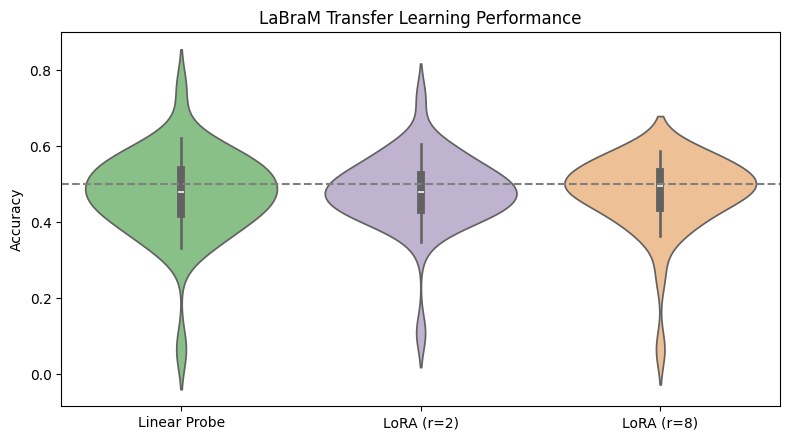

In [41]:
cache_file = paths.tables_dir / "exp7_pretrained_models_results.csv"

try:
    df_tf = pd.read_csv(cache_file)
    summary = df_tf.groupby(["Task", "Strategy"])["Accuracy"].mean().reset_index()
    print("\n=== Transfer Learning Summary ===")
    print(summary.to_string(index=False))

    plt.figure(figsize=(8, 4.5))
    sns.violinplot(data=df_tf, x="Strategy", y="Accuracy", hue="Strategy", palette="Accent")
    plt.axhline(0.5, linestyle="--", color="gray")
    plt.title("LaBraM Transfer Learning Performance")
    plt.ylabel("Accuracy")
    plt.xlabel("")
    plt.tight_layout()
    plt.savefig(paths.figures_dir / f"experiment7_labram_transfer_comparison.png", dpi=300)
    plt.show()
except FileNotFoundError:
    import os
    import torch
    import torch.nn as nn
    from huggingface_hub import hf_hub_download
    !pip install -q braindecode
    from braindecode.models import InterpolatedLaBraM
    from br_analysis.torch_training import build_dataloader, _evaluate
    from br_analysis.pretrained import prepare_lora_backbone, load_backbone_weights
    import seaborn as sns

    print("Stage 7: Foundation Models Transfer Learning")
    print("  -> Real pretrained LaBraM from HuggingFace: braindecode/labram-pretrained")
    print("  -> Linear Probe vs. LoRA parameter adaptation")

    cluster_chans = TARGET_BANDS_CLUSTERS["theta"] + TARGET_BANDS_CLUSTERS["alpha"]
    TARGET_LEN = 200

    tasks_dict = {
        "C vs IP": (X_subs_c, y_subs_c, dataset_c),
        "IM vs IP": (X_subs_im, y_subs_im, dataset_im),
    }

    def get_labram_checkpoint():
        checkpoint_path = None
        if os.path.exists("/kaggle/input"):
            for root, _, files in os.walk("/kaggle/input"):
                if "model.safetensors" in files and "labram" in root.lower():
                    checkpoint_path = Path(root) / "model.safetensors"
                    break
        if checkpoint_path is None:
            checkpoint_path = hf_hub_download(
                repo_id="braindecode/labram-pretrained",
                filename="model.safetensors",
            )
        return Path(checkpoint_path)

    labram_checkpoint = get_labram_checkpoint()
    print(f"Using LaBraM checkpoint: {labram_checkpoint}")

    def pad_or_crop_to_target_len(X, target_len=TARGET_LEN):
        if X.shape[-1] == target_len:
            return X
        if X.shape[-1] > target_len:
            return X[..., :target_len]
        pad_width = target_len - X.shape[-1]
        return np.pad(X, ((0, 0), (0, 0), (0, pad_width)), mode="edge")

    def unfreeze_labram_classifier(model):
        unfrozen = 0
        if hasattr(model, "get_classifier"):
            classifier = model.get_classifier()
            for param in classifier.parameters():
                param.requires_grad = True
                unfrozen += param.numel()
        for name, param in model.named_parameters():
            if any(key in name.lower() for key in ("head", "classifier", "final", "out_proj", "output")):
                param.requires_grad = True
                unfrozen += param.numel()
        return unfrozen

    def trainable_parameters_or_raise(model, *, context):
        params = [p for p in model.parameters() if p.requires_grad]
        if not params:
            head_params = unfreeze_labram_classifier(model)
            params = [p for p in model.parameters() if p.requires_grad]
        if not params:
            sample_names = [name for name, _ in list(model.named_parameters())[:20]]
            raise RuntimeError(
                f"No trainable parameters for {context}. " f"Available first parameter names: {sample_names}"
            )
        return params

    def make_real_labram(channel_names, n_outputs=2):
        ch_names = list(channel_names)
        info = mne.create_info(ch_names=ch_names, sfreq=128.0, ch_types="eeg")
        montage = mne.channels.make_standard_montage("standard_1005")
        info.set_montage(montage, on_missing="ignore")
        model = InterpolatedLaBraM(
            chs_info=info["chs"],
            n_times=TARGET_LEN,
            n_outputs=n_outputs,
            patch_size=200,
        )
        load_backbone_weights(model, labram_checkpoint, strict=False)
        return model

    transfer_results = []

    for task_lbl, (X_dict, y_dict, ds) in tasks_dict.items():
        print(f"\nRunning real LaBraM downstream transfer for: {task_lbl}")
        for sub in target_subjects:
            X_sub, y_sub = X_dict[sub], y_dict[sub]
            picks_idx = [ds.channel_names.index(ch) for ch in cluster_chans if ch in ds.channel_names]
            # Keep the original Stage-7 cluster/window comparison setup; LaBraM input is padded to pretrained length.
            t_mask = (ds.times >= 0.375) & (ds.times <= 1.242)
            X_crop = pad_or_crop_to_target_len(X_sub[:, picks_idx][..., t_mask])

            splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)
            for strategy in ["Linear Probe", "LoRA (r=2)", "LoRA (r=8)"]:
                for fold_idx, (train_idx, test_idx) in enumerate(splits[-2:], start=4):
                    X_tr, X_te = X_crop[train_idx], X_crop[test_idx]
                    y_tr, y_te = y_sub[train_idx], y_sub[test_idx]
                    X_tr, X_te = standardize_subject_wise(X_tr, X_te)

                    train_loader = build_dataloader(X_tr, y_tr, batch_size=8, shuffle=True, device=DEVICE)
                    val_loader = build_dataloader(X_te, y_te, batch_size=8, shuffle=False, device=DEVICE)

                    selected_channel_names = [ds.channel_names[i] for i in picks_idx]
                    backbone = make_real_labram(selected_channel_names, n_outputs=2)

                    if strategy == "Linear Probe":
                        for param in backbone.parameters():
                            param.requires_grad = False
                        unfreeze_labram_classifier(backbone)
                    elif strategy == "LoRA (r=2)":
                        prepare_lora_backbone(
                            backbone,
                            include_substrings=("attn", "mlp"),
                            exclude_substrings=("head", "classifier", "interpolation_layer"),
                            r=2,
                            alpha=4.0,
                            dropout=0.2,
                            train_classifier=True,
                        )
                    else:
                        prepare_lora_backbone(
                            backbone,
                            include_substrings=("attn", "mlp"),
                            exclude_substrings=("head", "classifier", "interpolation_layer"),
                            r=8,
                            alpha=16.0,
                            dropout=0.05,
                            train_classifier=True,
                        )

                    unfreeze_labram_classifier(backbone)
                    model = backbone.to(DEVICE)
                    optimizer = torch.optim.AdamW(
                        trainable_parameters_or_raise(model, context=f"LaBraM {strategy}"),
                        lr=3e-5,
                        weight_decay=1e-2 if strategy != "LoRA (r=8)" else 1e-4,
                    )
                    criterion = nn.CrossEntropyLoss()

                    for epoch in range(5):
                        model.train()
                        for bx, by in train_loader:
                            bx, by = bx.to(DEVICE), by.to(DEVICE)
                            optimizer.zero_grad(set_to_none=True)
                            out = model(bx)
                            loss = criterion(out, by)
                            loss.backward()
                            optimizer.step()

                    _, val_acc, _, _, _ = _evaluate(model, val_loader, DEVICE)
                    transfer_results.append(
                        {
                            "Subject": sub,
                            "Strategy": strategy,
                            "Fold": fold_idx,
                            "Accuracy": val_acc,
                            "Task": task_lbl,
                            "Backbone": "braindecode/labram-pretrained",
                            "Checkpoint": str(labram_checkpoint),
                        }
                    )

    df_tf = pd.DataFrame(transfer_results)
    df_tf.to_csv(cache_file, index=False)

### Experiment 8: Cohort-Level Joint Search (Optuna)

We replace the previous per-subject Optuna search with a cohort-level objective. Each trial proposes one shared configuration and evaluates it across all target subjects on development folds only. This prevents subject-specific winner's curse and makes the selected configuration interpretable as a common decoding recipe. The search is run independently for `c_vs_ip` and `im_vs_ip`.

Loaded cached cohort-level results for Experiment 8.

=== Cohort-Level Optuna Experiment-Guided Configurations ===
    Task  Objective Score  Mean Accuracy  Std Accuracy  Min Subject Accuracy Model Family Normalization Spatial      Band Time Scope                                                     Details                                                                                                                                                  Param Importances
 C vs IP         0.569633       0.593605      0.095888              0.425532      Riemann  trial_zscore     All Broadband       full                                      {'riemann_cov': 'oas'} {'band': 0.47347819924141277, 'time_scope': 0.2818134850401647, 'norm': 0.15045616097174802, 'spatial': 0.06718049160855794, 'model_family': 0.027071663138116722}
IM vs IP         0.558466       0.580945      0.089916              0.479167 Classical ML robust_scaler     ROI     Alpha       full {'ml_features': 'psd_welch', 'ml_lr_c': 

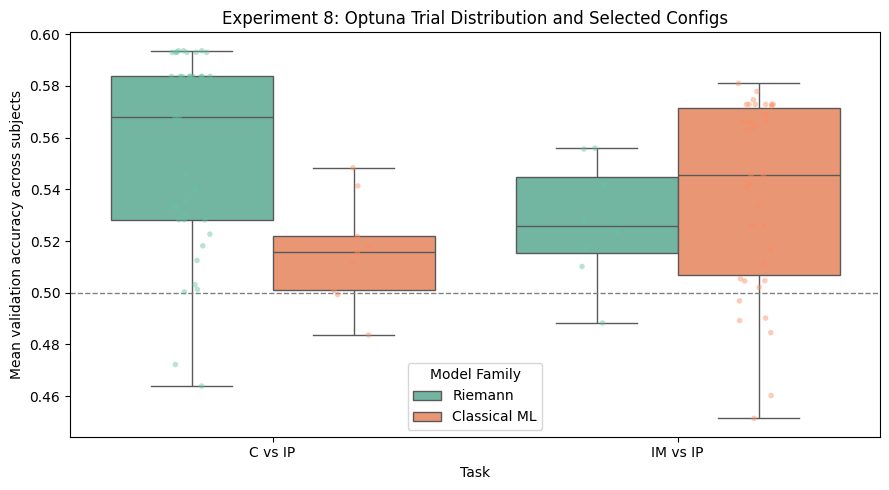


=== Experiment 8 Exploratory Marginal Effects (trial-level, non-causal) ===

-- Normalization --
    Task Normalization  count     mean      std
 C vs IP  trial_zscore     21 0.553111 0.040718
 C vs IP robust_scaler     17 0.551627 0.039386
 C vs IP        zscore      4 0.527295 0.020790
 C vs IP          none      4 0.515685 0.023468
IM vs IP robust_scaler     29 0.549675 0.031605
IM vs IP        zscore      5 0.538021 0.019484
IM vs IP          none      6 0.512677 0.021583
IM vs IP  trial_zscore      6 0.497170 0.026109

-- Spatial --
    Task Spatial  count     mean      std
 C vs IP     All     31 0.559297 0.039334
 C vs IP     ROI      8 0.527773 0.021620
 C vs IP Cluster      7 0.514932 0.022439
IM vs IP     ROI     31 0.544090 0.034838
IM vs IP     All      8 0.522185 0.028200
IM vs IP Cluster      7 0.520784 0.031152

-- Band --
    Task          Band  count     mean      std
 C vs IP         Alpha     20 0.556730 0.029120
 C vs IP     Broadband     20 0.552609 0.040204
 C vs

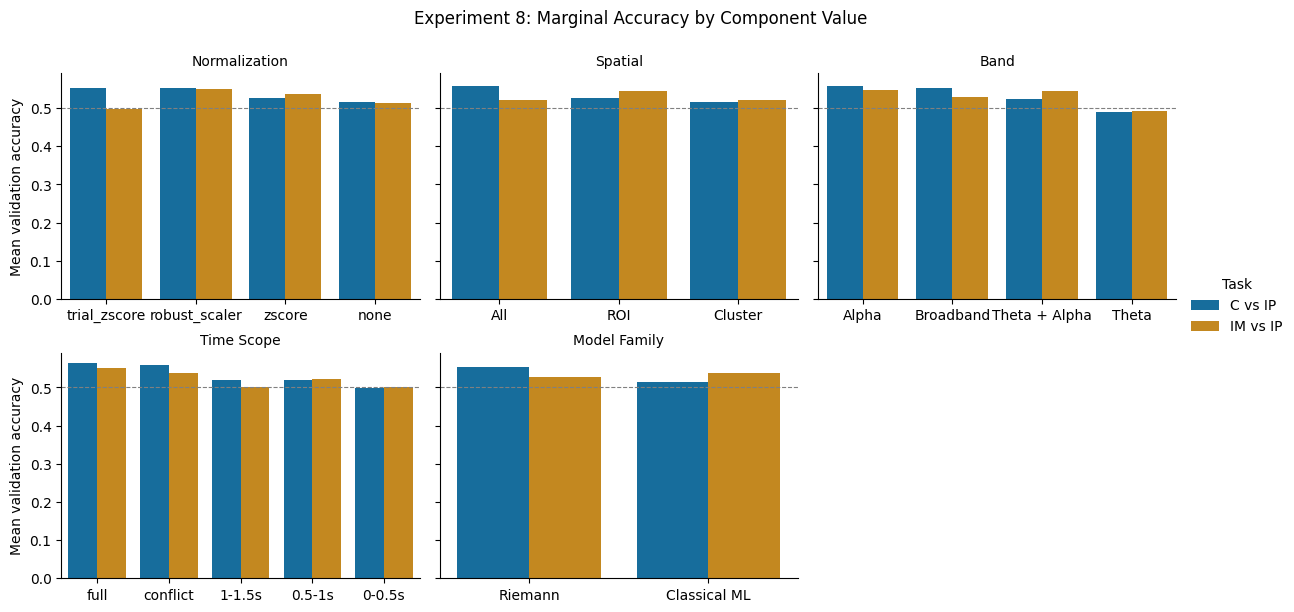

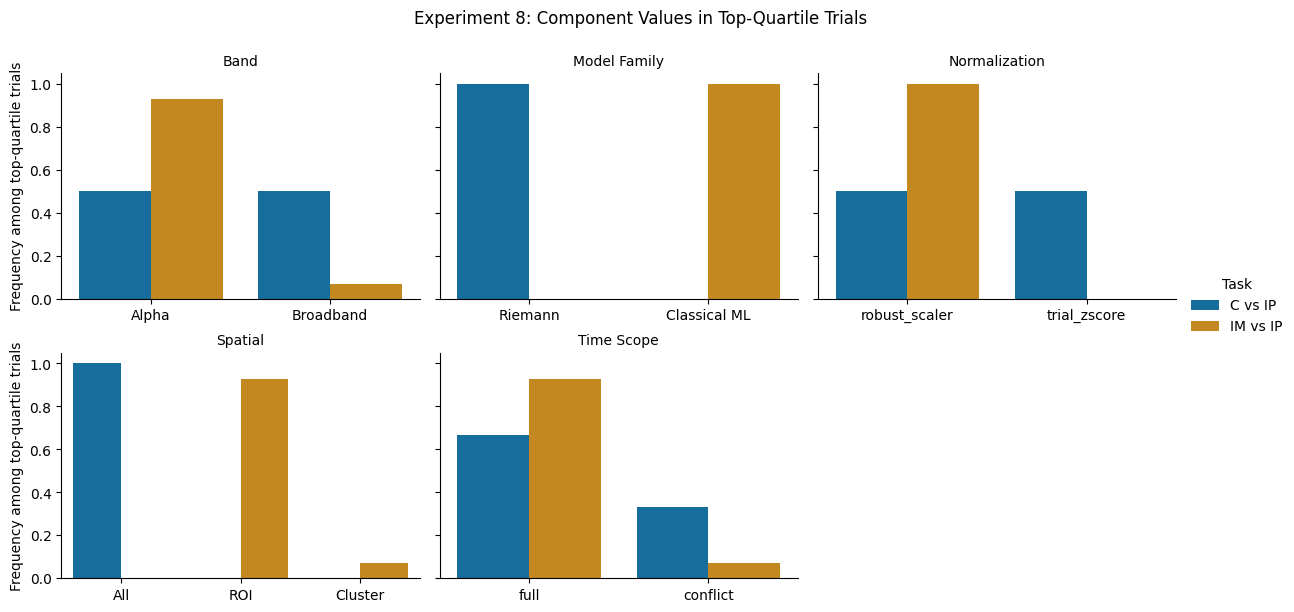

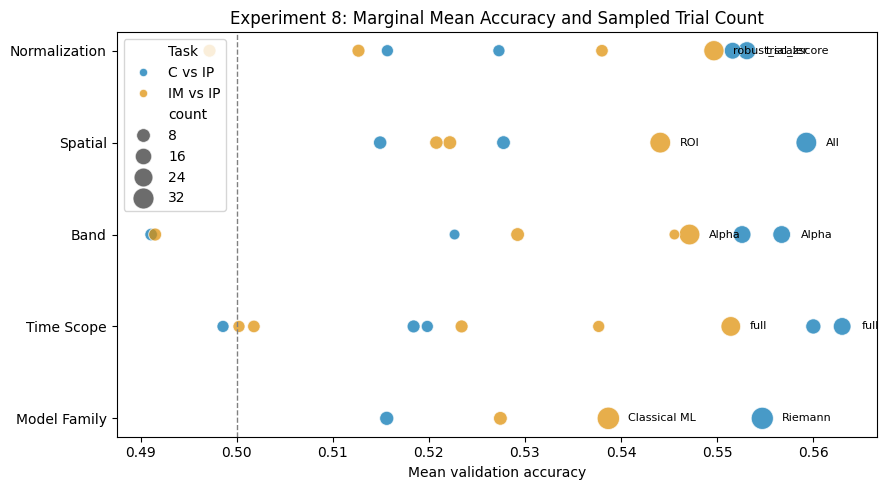

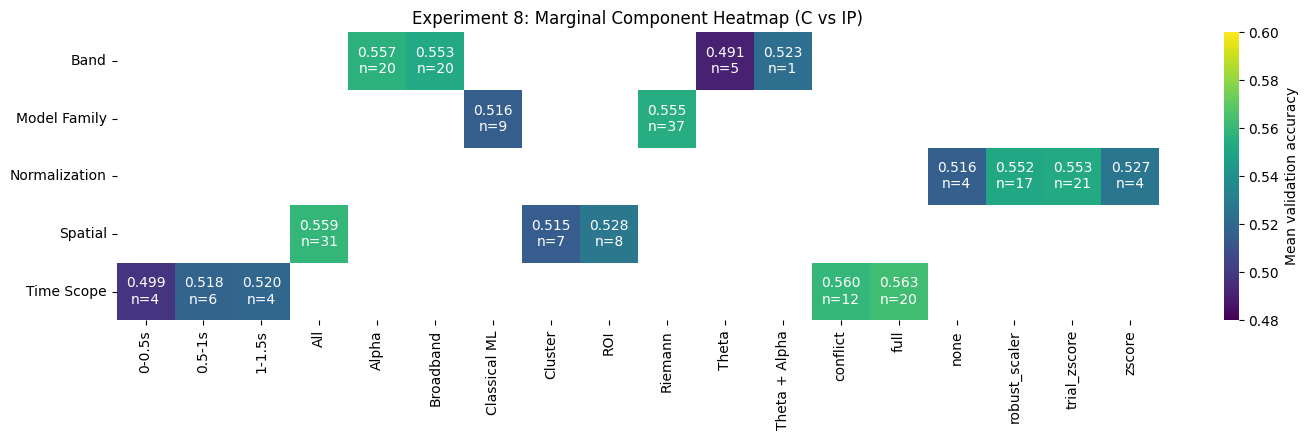

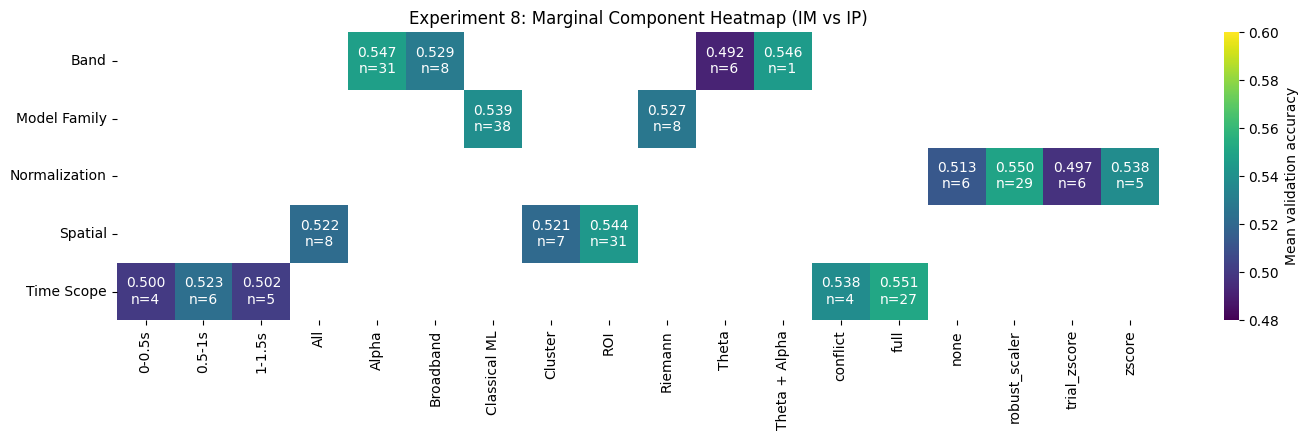

In [54]:
exp8_best_file = paths.tables_dir / "exp8_cohort_optuna_best.csv"
exp8_trials_file = paths.tables_dir / "exp8_cohort_optuna_trials.csv"

def summarize_exp8_trial_effects(df_trials):
    """Exploratory marginal summaries from sampled Optuna trials, not causal ablations."""
    if df_trials.empty or "Mean Accuracy" not in df_trials.columns:
        return None, None
    factor_cols = ["Normalization", "Spatial", "Band", "Time Scope", "Model Family"]
    marginal_tables = []
    print("\n=== Experiment 8 Exploratory Marginal Effects (trial-level, non-causal) ===")
    for factor in factor_cols:
        if factor not in df_trials.columns:
            continue
        summary = (
            df_trials.groupby(["Task", factor])["Mean Accuracy"]
            .agg(["count", "mean", "std"])
            .reset_index()
            .sort_values(["Task", "mean"], ascending=[True, False])
        )
        summary["Factor"] = factor
        summary["Value"] = summary[factor].astype(str)
        marginal_tables.append(summary[["Task", "Factor", "Value", "count", "mean", "std"]])
        print(f"\n-- {factor} --")
        print(summary.drop(columns=["Factor", "Value"]).to_string(index=False))

    top_rows = []
    for task_lbl, task_df in df_trials.groupby("Task"):
        threshold = task_df["Mean Accuracy"].quantile(0.75)
        top_df = task_df[task_df["Mean Accuracy"] >= threshold]
        for factor in factor_cols:
            if factor not in top_df.columns:
                continue
            freqs = top_df[factor].value_counts(normalize=True)
            for value, freq in freqs.items():
                top_rows.append({"Task": task_lbl, "Factor": factor, "Value": value, "Top Quartile Frequency": freq})
    top_summary = None
    if top_rows:
        top_summary = pd.DataFrame(top_rows).sort_values(
            ["Task", "Factor", "Top Quartile Frequency"], ascending=[True, True, False]
        )
        print("\n=== Experiment 8 Top-Quartile Component Frequencies ===")
        print(top_summary.to_string(index=False))
    marginal_summary = pd.concat(marginal_tables, ignore_index=True) if marginal_tables else None
    return marginal_summary, top_summary


def plot_exp8_trial_summary(df_trials, df_best):
    if df_trials.empty or "Mean Accuracy" not in df_trials.columns:
        return
    factor_cols = ["Normalization", "Spatial", "Band", "Time Scope", "Model Family"]

    plt.figure(figsize=(9, 5))
    sns.boxplot(data=df_trials, x="Task", y="Mean Accuracy", hue="Model Family", palette="Set2", showfliers=False)
    sns.stripplot(
        data=df_trials,
        x="Task",
        y="Mean Accuracy",
        hue="Model Family",
        dodge=True,
        palette="Set2",
        alpha=0.45,
        size=4,
        legend=False,
    )
    plt.axhline(0.5, linestyle="--", color="gray", linewidth=1)
    plt.title("Experiment 8: Optuna Trial Distribution and Selected Configs")
    plt.ylabel("Mean validation accuracy across subjects")
    plt.tight_layout()
    plt.savefig(paths.figures_dir / "experiment8_cohort_optuna_trials.png", dpi=300)
    plt.show()

    marginal, top_summary = summarize_exp8_trial_effects(df_trials)
    if marginal is not None and not marginal.empty:
        g = sns.catplot(
            data=marginal,
            x="Value",
            y="mean",
            hue="Task",
            col="Factor",
            col_wrap=3,
            kind="bar",
            sharex=False,
            sharey=True,
            palette="colorblind",
            height=3.2,
            aspect=1.25,
        )
        g.set_axis_labels("", "Mean validation accuracy")
        g.set_titles("{col_name}")
        for ax in g.axes.flatten():
            ax.axhline(0.5, linestyle="--", color="gray", linewidth=0.8)
            ax.tick_params(axis="x", rotation=0)
        g.fig.subplots_adjust(top=0.88)
        g.fig.suptitle("Experiment 8: Marginal Accuracy by Component Value")
        g.savefig(paths.figures_dir / "experiment8_marginal_component_means.png", dpi=300)
        plt.show()

    if top_summary is not None and not top_summary.empty:
        g = sns.catplot(
            data=top_summary,
            x="Value",
            y="Top Quartile Frequency",
            hue="Task",
            col="Factor",
            col_wrap=3,
            kind="bar",
            sharex=False,
            sharey=True,
            palette="colorblind",
            height=3.2,
            aspect=1.25,
        )
        g.set_axis_labels("", "Frequency among top-quartile trials")
        g.set_titles("{col_name}")
        for ax in g.axes.flatten():
            ax.tick_params(axis="x", rotation=0)
        g.fig.subplots_adjust(top=0.88)
        g.fig.suptitle("Experiment 8: Component Values in Top-Quartile Trials")
        g.savefig(paths.figures_dir / "experiment8_top_quartile_components.png", dpi=300)
        plt.show()

    if marginal is not None and not marginal.empty:
        marginal.to_csv(paths.tables_dir / "experiment8_marginal_component_means.csv", index=False)
        top_by_factor = (
            marginal.sort_values(["Task", "Factor", "mean"], ascending=[True, True, False])
            .groupby(["Task", "Factor"], as_index=False)
            .first()
        )
        plt.figure(figsize=(9, 5))
        sns.scatterplot(
            data=marginal,
            x="mean",
            y="Factor",
            hue="Task",
            size="count",
            sizes=(60, 260),
            alpha=0.72,
            palette="colorblind",
        )
        for _, row in top_by_factor.iterrows():
            plt.text(row["mean"] + 0.002, row["Factor"], str(row["Value"]), va="center", fontsize=8)
        plt.axvline(0.5, linestyle="--", color="gray", linewidth=1)
        plt.title("Experiment 8: Marginal Mean Accuracy and Sampled Trial Count")
        plt.xlabel("Mean validation accuracy")
        plt.ylabel("")
        plt.tight_layout()
        plt.savefig(paths.figures_dir / "experiment8_marginal_bubble_summary.png", dpi=300)
        plt.show()

        for task_lbl, task_df in marginal.groupby("Task"):
            heat = task_df.pivot_table(index="Factor", columns="Value", values="mean", aggfunc="mean")
            counts = task_df.pivot_table(index="Factor", columns="Value", values="count", aggfunc="sum", fill_value=0)
            annotations = heat.copy().astype(object)
            for ridx in heat.index:
                for col in heat.columns:
                    val = heat.loc[ridx, col]
                    n = int(counts.loc[ridx, col]) if col in counts.columns and ridx in counts.index else 0
                    annotations.loc[ridx, col] = "" if pd.isna(val) else f"{val:.3f}\nn={n}"
            plt.figure(figsize=(max(8, 0.8 * len(heat.columns)), 4.5))
            sns.heatmap(heat, annot=annotations, fmt="", cmap="viridis", vmin=0.48, vmax=0.60, cbar_kws={"label": "Mean validation accuracy"})
            plt.title(f"Experiment 8: Marginal Component Heatmap ({task_lbl})")
            plt.xlabel("")
            plt.ylabel("")
            plt.tight_layout()
            tag = "c_ip" if task_lbl == "C vs IP" else "im_ip"
            plt.savefig(paths.figures_dir / f"experiment8_marginal_heatmap_{tag}.png", dpi=300)
            plt.show()

    if top_summary is not None and not top_summary.empty:
        top_summary.to_csv(paths.tables_dir / "experiment8_top_quartile_component_frequencies.csv", index=False)

try:
    df_opt_best = pd.read_csv(exp8_best_file)
    df_opt_trials = pd.read_csv(exp8_trials_file)
    print("Loaded cached cohort-level results for Experiment 8.")

    print("\n=== Cohort-Level Optuna Experiment-Guided Configurations ===")
    print(df_opt_best.to_string(index=False))

    plot_exp8_trial_summary(df_opt_trials, df_opt_best)
except FileNotFoundError:
    %pip install -q optuna
    import optuna
    from optuna.importance import get_param_importances

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    from sklearn.linear_model import LogisticRegression
    from sklearn.preprocessing import StandardScaler, RobustScaler
    from sklearn.metrics import accuracy_score
    from mne.filter import filter_data
    from scipy.signal import welch
    import warnings

    warnings.filterwarnings("ignore")

    roi_chans = ["P7", "P8", "PO7", "PO3", "POz", "PO4", "PO8", "O1", "Oz", "O2", "Fz", "FCz", "Cz"]
    cluster_chans = TARGET_BANDS_CLUSTERS["theta"] + TARGET_BANDS_CLUSTERS["alpha"]

    task_spaces = {
        "C vs IP": (X_subs_c, y_subs_c, dataset_c),
        "IM vs IP": (X_subs_im, y_subs_im, dataset_im),
    }

    search_space = {
        "norm": ["zscore", "none", "trial_zscore", "robust_scaler"],
        "spatial": ["Cluster", "ROI", "All"],
        "band": ["Theta", "Alpha", "Theta + Alpha", "Broadband"],
        "time_scope": ["conflict", "full", "0.5-1s", "0-0.5s", "1-1.5s"],
        "model_family": ["Riemann", "Classical ML"],
    }

    def regularize_spd_matrices(mats, eps=1e-5):
        mats = np.asarray(mats, dtype=np.float64)
        mats = np.nan_to_num(mats, nan=0.0, posinf=0.0, neginf=0.0)
        mats = 0.5 * (mats + np.swapaxes(mats, -1, -2))
        out = np.empty_like(mats)
        eye = np.eye(mats.shape[-1], dtype=np.float64)
        for i, mat in enumerate(mats):
            eigvals, eigvecs = np.linalg.eigh(mat + eps * eye)
            eigvals = np.maximum(eigvals, eps)
            repaired = (eigvecs * eigvals) @ eigvecs.T
            out[i] = 0.5 * (repaired + repaired.T)
        return out

    def config_arrays(X_sub, ds, *, spatial, band, time_scope):
        if spatial == "ROI":
            picks = [ch for ch in roi_chans if ch in ds.channel_names]
        elif spatial == "Cluster":
            picks = [ch for ch in cluster_chans if ch in ds.channel_names]
        else:
            picks = ds.channel_names
        picks_idx = [ds.channel_names.index(ch) for ch in picks]

        if band == "Theta":
            lf, hf = 5.0, 7.0
        elif band == "Alpha":
            lf, hf = 8.0, 12.0
        elif band == "Theta + Alpha":
            lf, hf = 5.0, 12.0
        else:
            lf, hf = 1.0, 40.0

        if time_scope == "conflict":
            t_mask = (ds.times >= 0.375) & (ds.times <= 1.242)
        elif time_scope == "0.5-1s":
            t_mask = (ds.times >= 0.5) & (ds.times <= 1.0)
        elif time_scope == "0-0.5s":
            t_mask = (ds.times >= 0.0) & (ds.times <= 0.5)
        elif time_scope == "1-1.5s":
            t_mask = (ds.times >= 1.0) & (ds.times <= 1.5)
        else:
            t_mask = (ds.times >= 0.0) & (ds.times <= 1.5)

        X_crop = X_sub[:, picks_idx][..., t_mask]
        X_filt = filter_data(X_crop.astype(np.float64), sfreq=128.0, l_freq=lf, h_freq=hf, method="iir", verbose=False)
        return X_filt, lf, hf

    def eval_shared_config(X_dict, y_dict, ds, params):
        subject_scores = []
        for sub in target_subjects:
            X_sub, y_sub = X_dict[sub], y_dict[sub]
            splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)
            if not splits:
                continue
            tr_idx, val_idx = splits[-1]
            X_filt, lf, hf = config_arrays(
                X_sub,
                ds,
                spatial=params["spatial"],
                band=params["band"],
                time_scope=params["time_scope"],
            )
            X_tr, X_val = X_filt[tr_idx], X_filt[val_idx]

            if params["model_family"] == "Riemann":
                if params["norm"] == "zscore":
                    X_tr, X_val = standardize_standard_scaler(X_tr, X_val)
                elif params["norm"] == "trial_zscore":
                    X_tr, X_val = standardize_trial_wise(X_tr, X_val)
                elif params["norm"] == "robust_scaler":
                    X_tr, X_val = standardize_robust_scaler(X_tr, X_val)
                else:
                    X_tr, X_val = X_tr * 1e6, X_val * 1e6
                cov = Covariances(estimator=params.get("riemann_cov", "oas"))
                X_tr_cov = regularize_spd_matrices(cov.fit_transform(X_tr))
                X_val_cov = regularize_spd_matrices(cov.transform(X_val))
                ts = TangentSpace(metric="riemann")
                X_tr_ts = ts.fit_transform(X_tr_cov, y_sub[tr_idx])
                X_val_ts = ts.transform(X_val_cov)
                clf = LDA(solver="lsqr", shrinkage="auto")
                clf.fit(X_tr_ts, y_sub[tr_idx])
                pred = clf.predict(X_val_ts)
            else:
                if params.get("ml_features", "hilbert_envelope") == "hilbert_envelope":
                    feats_tr = np.abs(hilbert(X_tr, axis=-1)).mean(axis=-1)
                    feats_val = np.abs(hilbert(X_val, axis=-1)).mean(axis=-1)
                else:
                    f, psd_tr = welch(X_tr, fs=128.0, axis=-1)
                    _, psd_val = welch(X_val, fs=128.0, axis=-1)
                    f_mask = (f >= lf) & (f <= hf)
                    feats_tr = psd_tr[..., f_mask].mean(axis=-1)
                    feats_val = psd_val[..., f_mask].mean(axis=-1)
                if params["norm"] == "zscore":
                    scaler = StandardScaler()
                    feats_tr = scaler.fit_transform(feats_tr)
                    feats_val = scaler.transform(feats_val)
                elif params["norm"] == "trial_zscore":
                    feats_tr = (feats_tr - feats_tr.mean(axis=-1, keepdims=True)) / np.maximum(feats_tr.std(axis=-1, keepdims=True), 1e-6)
                    feats_val = (feats_val - feats_val.mean(axis=-1, keepdims=True)) / np.maximum(feats_val.std(axis=-1, keepdims=True), 1e-6)
                elif params["norm"] == "robust_scaler":
                    scaler = RobustScaler()
                    feats_tr = scaler.fit_transform(feats_tr)
                    feats_val = scaler.transform(feats_val)
                else:
                    feats_tr = feats_tr * 1e6
                    feats_val = feats_val * 1e6
                clf = LogisticRegression(
                    C=params.get("ml_lr_c", 1.0), penalty="l2", class_weight="balanced", max_iter=1000, random_state=42
                )
                clf.fit(feats_tr, y_sub[tr_idx])
                pred = clf.predict(feats_val)
            subject_scores.append(float(accuracy_score(y_sub[val_idx], pred)))
        return subject_scores

    best_rows = []
    trial_rows = []

    for task_lbl, (X_dict, y_dict, ds) in task_spaces.items():
        print(f"Optimizing one shared configuration for {task_lbl}...")

        def objective(trial):
            params = {
                "norm": trial.suggest_categorical("norm", search_space["norm"]),
                "spatial": trial.suggest_categorical("spatial", search_space["spatial"]),
                "band": trial.suggest_categorical("band", search_space["band"]),
                "time_scope": trial.suggest_categorical("time_scope", search_space["time_scope"]),
                "model_family": trial.suggest_categorical("model_family", search_space["model_family"]),
            }
            if params["model_family"] == "Riemann":
                params["riemann_cov"] = trial.suggest_categorical("riemann_cov", ["oas", "lwf"])
            else:
                params["ml_features"] = trial.suggest_categorical("ml_features", ["hilbert_envelope", "psd_welch"])
                params["ml_lr_c"] = trial.suggest_float("ml_lr_c", 1e-2, 1e2, log=True)
            try:
                scores = eval_shared_config(X_dict, y_dict, ds, params)
            except ValueError as exc:
                raise optuna.TrialPruned(f"Invalid trial: {exc}")
            if not scores:
                raise optuna.TrialPruned("No valid subject scores")
            mean_score = float(np.mean(scores))
            std_score = float(np.std(scores))
            min_score = float(np.min(scores))
            # Penalization for having more variance, we want stable results, not one-off high scores
            stable_score = mean_score - 0.5 * std_score
            trial.set_user_attr("subject_scores", scores)
            trial.set_user_attr("mean_accuracy", mean_score)
            trial.set_user_attr("std_accuracy", std_score)
            trial.set_user_attr("min_subject_accuracy", min_score)
            return stable_score

        study = optuna.create_study(direction="maximize")
        study.optimize(objective, n_trials=45)

        for trial in study.trials:
            if trial.value is None:
                continue
            scores = trial.user_attrs.get("subject_scores", [])
            trial_rows.append(
                {
                    "Task": task_lbl,
                    "Trial": trial.number,
                    "Objective Score": trial.value,
                    "Mean Accuracy": trial.user_attrs.get("mean_accuracy", np.nan),
                    "Std Accuracy": trial.user_attrs.get("std_accuracy", np.nan),
                    "Min Subject Accuracy": trial.user_attrs.get("min_subject_accuracy", np.nan),
                    "Model Family": trial.params.get("model_family"),
                    "Normalization": trial.params.get("norm"),
                    "Spatial": trial.params.get("spatial"),
                    "Band": trial.params.get("band"),
                    "Time Scope": trial.params.get("time_scope"),
                    "Details": str({k: v for k, v in trial.params.items() if k not in ["model_family", "norm", "spatial", "band", "time_scope"]}),
                }
            )

        best = study.best_trial
        scores = best.user_attrs.get("subject_scores", [])
        try:
            importances = get_param_importances(study)
        except Exception:
            importances = {}
        best_rows.append(
            {
                "Task": task_lbl,
                "Objective Score": best.value,
                "Mean Accuracy": best.user_attrs.get("mean_accuracy", np.nan),
                "Std Accuracy": best.user_attrs.get("std_accuracy", np.nan),
                "Min Subject Accuracy": best.user_attrs.get("min_subject_accuracy", np.nan),
                "Model Family": best.params.get("model_family"),
                "Normalization": best.params.get("norm"),
                "Spatial": best.params.get("spatial"),
                "Band": best.params.get("band"),
                "Time Scope": best.params.get("time_scope"),
                "Details": str({k: v for k, v in best.params.items() if k not in ["model_family", "norm", "spatial", "band", "time_scope"]}),
                "Param Importances": str(importances),
            }
        )
        print(f"  Best shared {task_lbl} mean accuracy: {best.user_attrs.get('mean_accuracy', np.nan):.4f} | objective: {best.value:.4f} | {best.params}")

    df_opt_best = pd.DataFrame(best_rows)
    df_opt_trials = pd.DataFrame(trial_rows)
    df_opt_best.to_csv(exp8_best_file, index=False)
    df_opt_trials.to_csv(exp8_trials_file, index=False)
    summarize_exp8_trial_effects(df_opt_trials)
    print("Experiment 8 cohort-level search executed and saved to cache.")

### Experiment 9: DL Cohort-Level Tuning (Subject-Independent, Model-Specific Tuning)

We use Optuna for model-specific hyperparameters, where interactions between learning rate, regularization, width, and dropout are plausible. EEGNet, ST-GNN, ST-EEGFormer, and LaBraM are all included in the same cohort-level tuning stage. The transformer/foundation-model variants use a smaller Optuna budget than EEGNet/ST-GNN because they are substantially slower, but they remain part of the experiment.


=== Deep Learning Cohort-Level Tuning Summary ===
       Model     mean  std
      EEGNet 0.544701  0.0
      LaBraM 0.510642  0.0
ST-EEGFormer 0.503155  0.0
      ST-GNN 0.528827  0.0

Pretrained checkpoints used:
       Model                                                                                                                                            Checkpoint
ST-EEGFormer /root/.cache/huggingface/hub/models--eugenehp--ST-EEGFormer/snapshots/24c1f616ea0287fa6e4dba6d9278b34de772f80a/ST-EEGFormer_small_encoder.safetensors
      LaBraM              /root/.cache/huggingface/hub/models--braindecode--labram-pretrained/snapshots/0563b6c626e7b40d9a36653b763715db94d945d7/model.safetensors


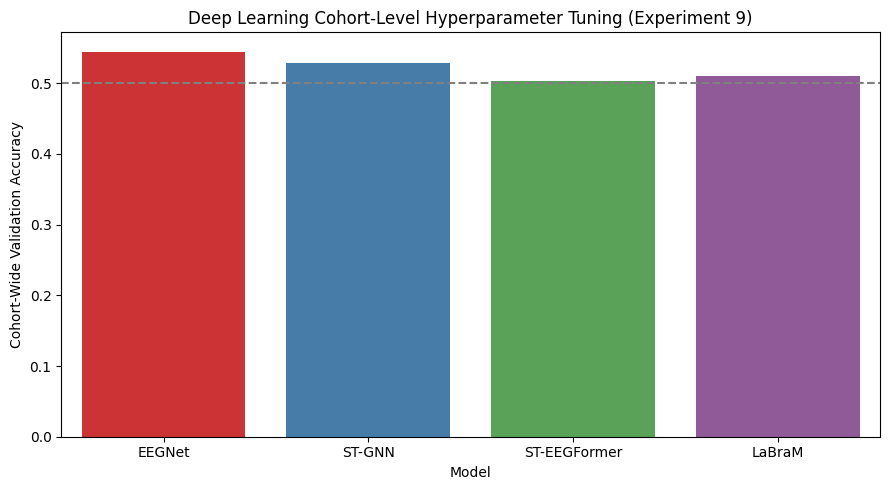

In [47]:
cache_file = paths.tables_dir / "exp9_dl_tuning_results.csv"


try:
    df_dl_opt = pd.read_csv(cache_file)
    # Calculate the std dev across subjects for each model to understand stability, in addition to mean accuracy
    summary = df_dl_opt.groupby("Model")["Accuracy"].agg(["mean", "std"]).reset_index()
    print("\n=== Deep Learning Cohort-Level Tuning Summary ===")
    print(summary.to_string(index=False))
    if "Checkpoint" in df_dl_opt.columns:
        ckpt = df_dl_opt[df_dl_opt["Checkpoint"].astype(str).str.len() > 0][["Model", "Checkpoint"]].drop_duplicates()
        if not ckpt.empty:
            print("\nPretrained checkpoints used:")
            print(ckpt.to_string(index=False))

    plt.figure(figsize=(9, 5))
    sns.barplot(data=df_dl_opt, x="Model", y="Accuracy", palette="Set1", hue="Model")
    plt.axhline(0.5, linestyle="--", color="gray")
    plt.title("Deep Learning Cohort-Level Hyperparameter Tuning (Experiment 9)")
    plt.ylabel("Cohort-Wide Validation Accuracy")
    plt.tight_layout()
    plt.savefig(paths.figures_dir / "experiment9_dl_tuning_results.png", dpi=300)
    plt.show()
except FileNotFoundError:
    import os
    import optuna

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    import torch
    import torch.nn as nn
    from huggingface_hub import hf_hub_download
    from braindecode.models import InterpolatedLaBraM
    from br_analysis import mae_vit_small_patch16
    from br_analysis.torch_training import build_dataloader, _evaluate
    from br_analysis.torch_models import EEGNet, STGNNChebConv
    from br_analysis.pretrained import (
        prepare_lora_backbone,
        load_backbone_weights,
        BackboneClassifier,
        align_channels_to_steegformer,
    )
    import warnings

    warnings.filterwarnings("ignore")

    def standardize_graph_train_test(X_train, X_test):
        mean = X_train.mean(axis=(0, 1), keepdims=True)
        std = np.maximum(X_train.std(axis=(0, 1), keepdims=True), 1e-6)
        return ((X_train - mean) / std).astype(np.float32), ((X_test - mean) / std).astype(np.float32)

    def pad_or_crop_to_target_len(X, target_len=200):
        if X.shape[-1] == target_len:
            return X
        if X.shape[-1] > target_len:
            return X[..., :target_len]
        return np.pad(X, ((0, 0), (0, 0), (0, target_len - X.shape[-1])), mode="edge")

    def find_or_download_checkpoint(*, repo_id, filename, kaggle_filename=None):
        checkpoint_path = None
        if os.path.exists("/kaggle/input"):
            target_name = kaggle_filename or filename
            for root, _, files in os.walk("/kaggle/input"):
                if target_name in files:
                    checkpoint_path = Path(root) / target_name
                    break
        if checkpoint_path is None:
            checkpoint_path = hf_hub_download(repo_id=repo_id, filename=filename)
        return Path(checkpoint_path)

    steeg_checkpoint = find_or_download_checkpoint(
        repo_id="eugenehp/ST-EEGFormer",
        filename="ST-EEGFormer_small_encoder.safetensors",
    )
    print(f"Using ST-EEGFormer checkpoint: {steeg_checkpoint}")
    labram_checkpoint = find_or_download_checkpoint(
        repo_id="braindecode/labram-pretrained",
        filename="model.safetensors",
    )
    print(f"Using LaBraM checkpoint: {labram_checkpoint}")

    cluster_chans = TARGET_BANDS_CLUSTERS["theta"] + TARGET_BANDS_CLUSTERS["alpha"]
    picks = [ch for ch in cluster_chans if ch in dataset_c.channel_names]
    picks_idx = [dataset_c.channel_names.index(ch) for ch in picks]
    t_mask = (dataset_c.times >= 0.375) & (dataset_c.times <= 1.242)
    graph_bands = {"theta": (5.0, 7.0), "alpha": (8.0, 12.0)}
    stgnn_adjacency = electrode_distance_adjacency(dataset_c.channel_names, threshold=0.35)

    X_cohort_crop = {sub: X_subs_c[sub][:, picks_idx][..., t_mask] for sub in target_subjects}
    X_cohort_graph = {
        sub: temporal_band_features(
            X_subs_c[sub], 128.0, bands=graph_bands, window_sec=0.500, step_sec=0.100, mode="de"
        )[0]
        for sub in target_subjects
    }
    X_cohort_steeg = {
        sub: align_channels_to_steegformer(X_subs_c[sub], list(dataset_c.channel_names)) for sub in target_subjects
    }
    X_cohort_labram = {sub: pad_or_crop_to_target_len(X_cohort_crop[sub], target_len=200) for sub in target_subjects}
    y_cohort = {sub: y_subs_c[sub] for sub in target_subjects}

    selected_labram_channel_names = [dataset_c.channel_names[i] for i in picks_idx]

    def unfreeze_classifier_like_modules(model):
        unfrozen = 0
        if hasattr(model, "get_classifier"):
            classifier = model.get_classifier()
            for param in classifier.parameters():
                param.requires_grad = True
                unfrozen += param.numel()
        for name, param in model.named_parameters():
            if any(key in name.lower() for key in ("head", "classifier", "final", "out_proj", "output")):
                param.requires_grad = True
                unfrozen += param.numel()
        return unfrozen

    def trainable_parameters_or_raise(model, *, context):
        params = [p for p in model.parameters() if p.requires_grad]
        if not params:
            unfreeze_classifier_like_modules(model)
            params = [p for p in model.parameters() if p.requires_grad]
        if not params:
            sample_names = [name for name, _ in list(model.named_parameters())[:20]]
            raise RuntimeError(
                f"No trainable parameters for {context}. " f"Available first parameter names: {sample_names}"
            )
        return params

    def make_real_steegformer(example_input, *, lora_r, lora_dropout):
        backbone = mae_vit_small_patch16()
        load_backbone_weights(backbone, steeg_checkpoint, strict=False)
        prepare_lora_backbone(
            backbone,
            include_substrings=("attn", "mlp"),
            exclude_substrings=("head", "classifier", "decoder", "patch_embed", "tokenizer"),
            r=lora_r,
            alpha=2.0 * lora_r,
            dropout=lora_dropout,
            train_classifier=False,
        )
        return BackboneClassifier(backbone, n_classes=2, example_input=torch.from_numpy(example_input[:1]))

    def make_real_labram(*, lora_r, lora_dropout):
        info = mne.create_info(ch_names=selected_labram_channel_names, sfreq=128.0, ch_types="eeg")
        montage = mne.channels.make_standard_montage("standard_1005")
        info.set_montage(montage, on_missing="ignore")
        model = InterpolatedLaBraM(
            chs_info=info["chs"],
            n_times=200,
            n_outputs=2,
            patch_size=200,
        )
        load_backbone_weights(model, labram_checkpoint, strict=False)
        prepare_lora_backbone(
            model,
            include_substrings=("attn", "mlp"),
            exclude_substrings=("head", "classifier", "interpolation_layer"),
            r=lora_r,
            alpha=2.0 * lora_r,
            dropout=lora_dropout,
            train_classifier=True,
        )
        unfreeze_classifier_like_modules(model)
        return model

    dl_models = ["EEGNet", "ST-GNN", "ST-EEGFormer", "LaBraM"]
    dl_tuning_results = []

    for model_name in dl_models:
        print(f"Tuning cohort hyperparameters for {model_name}...")

        def objective(trial):
            lr = (
                trial.suggest_float("lr", 1e-4, 3e-3, log=True)
                if model_name in ("EEGNet", "ST-GNN")
                else trial.suggest_float("lr", 1e-5, 3e-4, log=True)
            )
            wd = (
                trial.suggest_float("wd", 1e-6, 1e-3, log=True)
                if model_name in ("EEGNet", "ST-GNN")
                else trial.suggest_float("wd", 1e-5, 1e-2, log=True)
            )

            if model_name == "EEGNet":
                temporal_filt = trial.suggest_categorical("temporal_filt", [8, 16, 32])
                depth_mult = trial.suggest_categorical("depth_mult", [1, 2])
                drop_rate = trial.suggest_float("dropout", 0.15, 0.5)
            elif model_name == "ST-GNN":
                cheb_hidden = trial.suggest_categorical("cheb_hidden", [16, 24, 32])
                temporal_hidden = trial.suggest_categorical("temporal_hidden", [32, 48, 64])
                cheb_k = trial.suggest_categorical("cheb_K", [2, 3])
                drop_rate = trial.suggest_float("dropout", 0.15, 0.5)
            else:
                lora_r = trial.suggest_categorical("lora_r", [2, 4, 8])
                lora_drop = trial.suggest_float("lora_dropout", 0.01, 0.2)

            cohort_accs = []
            for sub in target_subjects:
                y_sub = y_cohort[sub]
                splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)
                tr_idx, val_idx = splits[-1]

                if model_name == "ST-GNN":
                    X_sub = X_cohort_graph[sub]
                    X_tr, X_val = standardize_graph_train_test(X_sub[tr_idx], X_sub[val_idx])
                elif model_name == "ST-EEGFormer":
                    X_sub = X_cohort_steeg[sub]
                    X_tr, X_val = standardize_train_test(X_sub[tr_idx], X_sub[val_idx])
                elif model_name == "LaBraM":
                    X_sub = X_cohort_labram[sub]
                    X_tr, X_val = standardize_train_test(X_sub[tr_idx], X_sub[val_idx])
                else:
                    X_sub = X_cohort_crop[sub]
                    X_tr, X_val = standardize_train_test(X_sub[tr_idx], X_sub[val_idx])

                batch_size = 8 if model_name in ("ST-EEGFormer", "LaBraM") else 16
                train_loader = build_dataloader(X_tr, y_sub[tr_idx], batch_size=batch_size, shuffle=True, device=DEVICE)
                val_loader = build_dataloader(
                    X_val, y_sub[val_idx], batch_size=batch_size, shuffle=False, device=DEVICE
                )

                if model_name == "EEGNet":
                    model = EEGNet(
                        n_channels=X_tr.shape[1],
                        n_times=X_tr.shape[2],
                        n_classes=2,
                        F1=temporal_filt,
                        D=depth_mult,
                        F2=temporal_filt * depth_mult,
                        dropout=drop_rate,
                    ).to(DEVICE)
                elif model_name == "ST-GNN":
                    model = STGNNChebConv(
                        n_nodes=X_tr.shape[2],
                        in_features=X_tr.shape[3],
                        adjacency=stgnn_adjacency,
                        n_classes=2,
                        cheb_hidden=cheb_hidden,
                        temporal_hidden=temporal_hidden,
                        K=cheb_k,
                        dropout=drop_rate,
                    ).to(DEVICE)
                elif model_name == "ST-EEGFormer":
                    model = make_real_steegformer(X_tr, lora_r=lora_r, lora_dropout=lora_drop).to(DEVICE)
                else:
                    model = make_real_labram(lora_r=lora_r, lora_dropout=lora_drop).to(DEVICE)

                optimizer = torch.optim.AdamW(
                    [p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=wd
                )
                criterion = torch.nn.CrossEntropyLoss()

                for _ in range(5):
                    model.train()
                    for bx, by in train_loader:
                        bx, by = bx.to(DEVICE), by.to(DEVICE)
                        optimizer.zero_grad(set_to_none=True)
                        loss = criterion(model(bx), by)
                        loss.backward()
                        optimizer.step()

                _, val_acc, _, _, _ = _evaluate(model, val_loader, DEVICE)
                cohort_accs.append(val_acc)

            return float(np.mean(cohort_accs))

        study = optuna.create_study(direction="maximize")
        n_trials = 3 if model_name in ("ST-EEGFormer", "LaBraM") else 5
        study.optimize(objective, n_trials=n_trials)

        best_trial = study.best_trial
        checkpoint = ""
        if model_name == "ST-EEGFormer":
            checkpoint = str(steeg_checkpoint)
        elif model_name == "LaBraM":
            checkpoint = str(labram_checkpoint)
        for sub in target_subjects:
            dl_tuning_results.append(
                {
                    "Subject": sub,
                    "Model": model_name,
                    "Accuracy": best_trial.value,
                    "Details": str(best_trial.params),
                    "Checkpoint": checkpoint,
                }
            )
        print(f"  {model_name} Cohort Best Accuracy: {best_trial.value:.4f}")

    df_dl_opt = pd.DataFrame(dl_tuning_results)
    df_dl_opt.to_csv(cache_file, index=False)
    print("Experiment 9 executed and saved to cache.")

### Experiment 10: Controlled Component Ablation

Experiment 10 turns the stable task-specific configurations from Experiment 8 into a local contribution analysis. For each task, the full shared configuration is evaluated first. Then one component at a time is replaced by a neutral/reference choice: all channels for spatial selection, broadband for band restriction, full epoch for time windowing, no normalization, or the alternate model family.

The plotted contribution is the accuracy lost when that component is removed or swapped: `full accuracy - ablated accuracy`. This is useful as a RAINBOW-style diagnostic, but it is still one-at-a-time and local to the Experiment 8 center. The colored segments should be read as marginal drops under single-component substitutions, not as independent causal effects that necessarily add up.


Experiment 10 controlled ablation executed and saved to cache.

=== Controlled Ablation Mean Deltas ===
    Task                        Variant  Delta vs Full
 C vs IP             Full shared config       0.000000
 C vs IP          Replace band -> Alpha      -0.061096
 C vs IP  Replace model -> Classical ML      -0.033016
 C vs IP           Replace norm -> none      -0.000860
 C vs IP         Replace spatial -> ROI      -0.054765
 C vs IP Replace time_scope -> conflict      -0.000633
IM vs IP             Full shared config       0.000000
IM vs IP      Replace band -> Broadband      -0.056319
IM vs IP       Replace model -> Riemann      -0.045562
IM vs IP           Replace norm -> none      -0.022174
IM vs IP         Replace spatial -> All      -0.062960
IM vs IP Replace time_scope -> conflict      -0.049834

=== Controlled Ablation Mean Contributions (Full - Ablated) ===
    Task     Component  Contribution
 C vs IP          Band      0.061096
 C vs IP  Model family      0.033016
 C vs

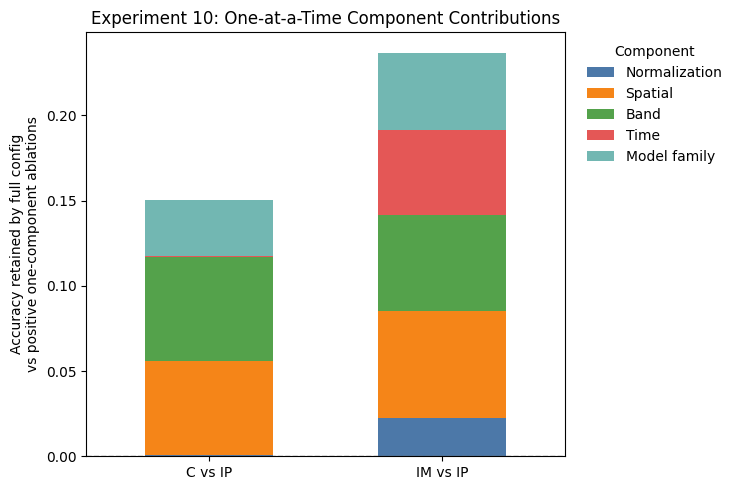

In [31]:
exp10_file = paths.tables_dir / "exp10_controlled_ablation_results.csv"


def exp10_component_label(variant):
    if variant == "Full shared config":
        return "Full"
    if "spatial" in variant:
        return "Spatial"
    if "band" in variant:
        return "Band"
    if "time_scope" in variant:
        return "Time"
    if "norm" in variant:
        return "Normalization"
    if "model" in variant:
        return "Model family"
    return "Other"


def plot_exp10_component_contributions(df_ablate):
    summary = df_ablate.groupby(["Task", "Variant"])["Delta vs Full"].mean().reset_index()
    print("\n=== Controlled Ablation Mean Deltas ===")
    print(summary.to_string(index=False))

    contrib = summary[summary["Variant"] != "Full shared config"].copy()
    contrib["Component"] = contrib["Variant"].map(exp10_component_label)
    contrib["Contribution"] = -contrib["Delta vs Full"]
    signed = contrib.groupby(["Task", "Component"], as_index=False)["Contribution"].mean()
    print("\n=== Controlled Ablation Mean Contributions (Full - Ablated) ===")
    print(signed.to_string(index=False))

    positive = signed.copy()
    positive["Positive Contribution"] = positive["Contribution"].clip(lower=0.0)
    pivot = positive.pivot_table(
        index="Task", columns="Component", values="Positive Contribution", aggfunc="sum", fill_value=0.0
    )
    component_order = ["Normalization", "Spatial", "Band", "Time", "Model family"]
    component_order = [c for c in component_order if c in pivot.columns] + [
        c for c in pivot.columns if c not in component_order
    ]
    colors = {
        "Normalization": "#4C78A8",
        "Spatial": "#F58518",
        "Band": "#54A24B",
        "Time": "#E45756",
        "Model family": "#72B7B2",
        "Other": "#B279A2",
    }

    ax = pivot[component_order].plot(
        kind="bar",
        stacked=True,
        figsize=(7.5, 5),
        color=[colors.get(c, "#9D755D") for c in component_order],
        width=0.55,
    )
    ax.axhline(0.0, linestyle="--", color="gray", linewidth=1)
    ax.set_title("Experiment 10: One-at-a-Time Component Contributions")
    ax.set_ylabel("Accuracy retained by full config\nvs positive one-component ablations")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title="Component", frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.savefig(paths.figures_dir / "experiment10_component_contributions.png", dpi=300)
    plt.show()


def exp10_has_all_component_checks(df_ablate):
    expected = {"Normalization", "Spatial", "Band", "Time", "Model family"}
    if df_ablate.empty or not {"Task", "Variant"}.issubset(df_ablate.columns):
        return False
    for _, task_df in df_ablate.groupby("Task"):
        observed = set(task_df.loc[task_df["Variant"] != "Full shared config", "Variant"].map(exp10_component_label))
        if not expected.issubset(observed):
            return False
    return True


try:
    df_ablate = pd.read_csv(exp10_file)
    if not exp10_has_all_component_checks(df_ablate):
        raise FileNotFoundError("Cached Experiment 10 is missing one or more component checks.")
    print("Loaded cached results for Experiment 10.")
    plot_exp10_component_contributions(df_ablate)
except FileNotFoundError:
    from sklearn.linear_model import LogisticRegression
    from sklearn.preprocessing import StandardScaler, RobustScaler
    from sklearn.metrics import accuracy_score
    from mne.filter import filter_data
    from scipy.signal import welch

    roi_chans = ["P7", "P8", "PO7", "PO3", "POz", "PO4", "PO8", "O1", "Oz", "O2", "Fz", "FCz", "Cz"]
    cluster_chans = TARGET_BANDS_CLUSTERS["theta"] + TARGET_BANDS_CLUSTERS["alpha"]

    def regularize_spd_matrices(mats, eps=1e-5):
        mats = np.asarray(mats, dtype=np.float64)
        mats = np.nan_to_num(mats, nan=0.0, posinf=0.0, neginf=0.0)
        mats = 0.5 * (mats + np.swapaxes(mats, -1, -2))
        out = np.empty_like(mats)
        eye = np.eye(mats.shape[-1], dtype=np.float64)
        for i, mat in enumerate(mats):
            eigvals, eigvecs = np.linalg.eigh(mat + eps * eye)
            eigvals = np.maximum(eigvals, eps)
            repaired = (eigvecs * eigvals) @ eigvecs.T
            out[i] = 0.5 * (repaired + repaired.T)
        return out

    def config_arrays(X_sub, ds, *, spatial, band, time_scope):
        if spatial == "ROI":
            picks = [ch for ch in roi_chans if ch in ds.channel_names]
        elif spatial == "Cluster":
            picks = [ch for ch in cluster_chans if ch in ds.channel_names]
        else:
            picks = ds.channel_names
        picks_idx = [ds.channel_names.index(ch) for ch in picks]
        if band == "Theta":
            lf, hf = 5.0, 7.0
        elif band == "Alpha":
            lf, hf = 8.0, 12.0
        elif band == "Theta + Alpha":
            lf, hf = 5.0, 12.0
        else:
            lf, hf = 1.0, 40.0
        if time_scope == "conflict":
            t_mask = (ds.times >= 0.375) & (ds.times <= 1.242)
        elif time_scope == "0.5-1s":
            t_mask = (ds.times >= 0.5) & (ds.times <= 1.0)
        elif time_scope == "0-0.5s":
            t_mask = (ds.times >= 0.0) & (ds.times <= 0.5)
        elif time_scope == "1-1.5s":
            t_mask = (ds.times >= 1.0) & (ds.times <= 1.5)
        else:
            t_mask = (ds.times >= 0.0) & (ds.times <= 1.5)
        X_crop = X_sub[:, picks_idx][..., t_mask]
        X_filt = filter_data(X_crop.astype(np.float64), sfreq=128.0, l_freq=lf, h_freq=hf, method="iir", verbose=False)
        return X_filt, lf, hf

    def eval_shared_config(X_dict, y_dict, ds, params):
        subject_scores = []
        subject_names = []
        for sub in target_subjects:
            X_sub, y_sub = X_dict[sub], y_dict[sub]
            splits = stratified_group_splits(y_sub, groups=chronological_group_labels(len(y_sub)), n_splits=5)
            if not splits:
                continue
            tr_idx, val_idx = splits[-1]
            X_filt, lf, hf = config_arrays(
                X_sub, ds, spatial=params["spatial"], band=params["band"], time_scope=params["time_scope"]
            )
            X_tr, X_val = X_filt[tr_idx], X_filt[val_idx]
            if params["model_family"] == "Riemann":
                if params["norm"] == "zscore":
                    X_tr, X_val = standardize_standard_scaler(X_tr, X_val)
                elif params["norm"] == "trial_zscore":
                    X_tr, X_val = standardize_trial_wise(X_tr, X_val)
                elif params["norm"] == "robust_scaler":
                    X_tr, X_val = standardize_robust_scaler(X_tr, X_val)
                else:
                    X_tr, X_val = X_tr * 1e6, X_val * 1e6
                cov = Covariances(estimator=params.get("riemann_cov", "oas"))
                X_tr_cov = regularize_spd_matrices(cov.fit_transform(X_tr))
                X_val_cov = regularize_spd_matrices(cov.transform(X_val))
                ts = TangentSpace(metric="riemann")
                X_tr_ts = ts.fit_transform(X_tr_cov, y_sub[tr_idx])
                X_val_ts = ts.transform(X_val_cov)
                clf = LDA(solver="lsqr", shrinkage="auto")
                clf.fit(X_tr_ts, y_sub[tr_idx])
                pred = clf.predict(X_val_ts)
            else:
                if params.get("ml_features", "hilbert_envelope") == "hilbert_envelope":
                    feats_tr = np.abs(hilbert(X_tr, axis=-1)).mean(axis=-1)
                    feats_val = np.abs(hilbert(X_val, axis=-1)).mean(axis=-1)
                else:
                    f, psd_tr = welch(X_tr, fs=128.0, axis=-1)
                    _, psd_val = welch(X_val, fs=128.0, axis=-1)
                    f_mask = (f >= lf) & (f <= hf)
                    feats_tr = psd_tr[..., f_mask].mean(axis=-1)
                    feats_val = psd_val[..., f_mask].mean(axis=-1)
                if params["norm"] == "zscore":
                    scaler = StandardScaler()
                    feats_tr = scaler.fit_transform(feats_tr)
                    feats_val = scaler.transform(feats_val)
                elif params["norm"] == "trial_zscore":
                    feats_tr = (feats_tr - feats_tr.mean(axis=-1, keepdims=True)) / np.maximum(
                        feats_tr.std(axis=-1, keepdims=True), 1e-6
                    )
                    feats_val = (feats_val - feats_val.mean(axis=-1, keepdims=True)) / np.maximum(
                        feats_val.std(axis=-1, keepdims=True), 1e-6
                    )
                elif params["norm"] == "robust_scaler":
                    scaler = RobustScaler()
                    feats_tr = scaler.fit_transform(feats_tr)
                    feats_val = scaler.transform(feats_val)
                else:
                    feats_tr = feats_tr * 1e6
                    feats_val = feats_val * 1e6
                clf = LogisticRegression(
                    C=params.get("ml_lr_c", 1.0), penalty="l2", class_weight="balanced", max_iter=1000, random_state=42
                )
                clf.fit(feats_tr, y_sub[tr_idx])
                pred = clf.predict(feats_val)
            subject_names.append(sub)
            subject_scores.append(float(accuracy_score(y_sub[val_idx], pred)))
        return subject_names, subject_scores

    if "df_opt_best" not in globals():
        df_opt_best = pd.read_csv(paths.tables_dir / "exp8_cohort_optuna_best.csv")

    task_spaces = {
        "C vs IP": (X_subs_c, y_subs_c, dataset_c),
        "IM vs IP": (X_subs_im, y_subs_im, dataset_im),
    }

    def parse_details(details):
        import ast

        try:
            return ast.literal_eval(details) if isinstance(details, str) and details else {}
        except Exception:
            return {}

    ablation_rows = []
    for _, best_row in df_opt_best.iterrows():
        task_lbl = best_row["Task"]
        X_dict, y_dict, ds = task_spaces[task_lbl]
        full_params = {
            "model_family": best_row["Model Family"],
            "norm": best_row["Normalization"],
            "spatial": best_row["Spatial"],
            "band": best_row["Band"],
            "time_scope": best_row["Time Scope"],
        }
        full_params.update(parse_details(best_row.get("Details", "")))

        variants = [("Full shared config", full_params)]
        control_options = {
            "norm": ["none", "zscore", "robust_scaler", "trial_zscore"],
            "spatial": ["All", "ROI", "Cluster"],
            "band": ["Broadband", "Alpha", "Theta + Alpha", "Theta"],
            "time_scope": ["full", "conflict", "0.5-1s", "0-0.5s", "1-1.5s"],
        }
        for axis in ["norm", "spatial", "band", "time_scope"]:
            fallback = next(value for value in control_options[axis] if value != full_params.get(axis))
            changed = dict(full_params)
            changed[axis] = fallback
            variants.append((f"Replace {axis} -> {fallback}", changed))
        if full_params.get("model_family") == "Riemann":
            changed = dict(full_params)
            changed["model_family"] = "Classical ML"
            changed.setdefault("ml_features", "hilbert_envelope")
            changed.setdefault("ml_lr_c", 1.0)
            variants.append(("Replace model -> Classical ML", changed))
        else:
            changed = dict(full_params)
            changed["model_family"] = "Riemann"
            changed.setdefault("riemann_cov", "oas")
            variants.append(("Replace model -> Riemann", changed))

        variant_scores = {}
        for variant_name, params in variants:
            subject_names, scores = eval_shared_config(X_dict, y_dict, ds, params)
            variant_scores[variant_name] = (subject_names, scores)
        full_subjects, full_score_values = variant_scores["Full shared config"]
        full_scores = np.asarray(full_score_values, dtype=float)

        for variant_name, (subject_names, scores) in variant_scores.items():
            scores = np.asarray(scores, dtype=float)
            delta = scores - full_scores if subject_names == full_subjects else np.full_like(scores, np.nan)
            for sub, score, d in zip(subject_names, scores, delta):
                ablation_rows.append(
                    {
                        "Task": task_lbl,
                        "Subject": sub,
                        "Variant": variant_name,
                        "Accuracy": float(score),
                        "Full Accuracy": (
                            float(full_scores[full_subjects.index(sub)]) if sub in full_subjects else np.nan
                        ),
                        "Delta vs Full": float(d),
                    }
                )

    df_ablate = pd.DataFrame(ablation_rows)
    df_ablate.to_csv(exp10_file, index=False)
    print("Experiment 10 controlled ablation executed and saved to cache.")
    plot_exp10_component_contributions(df_ablate)

### Experiment 11: Generalization and Subject-Identity Controls

Experiment 11 is the final reality check, so it keeps two related but separate questions under one experiment number.

**Experiment 11A** asks whether a decoder transfers beyond the exact setting used for model selection. LOSO evaluates unseen-subject generalization, few-shot adaptation tests how much target-subject calibration helps, and cross-condition validation tests whether a C vs IP decoder carries over to IM vs IP.

**Experiment 11B** is not a perceptual-decoding benchmark. It is a subject-identity control: can the same feature space identify which participant produced a held-out trial? High subject-ID accuracy means the EEG representation contains strong individual fingerprints, so task-decoding results should be interpreted alongside LOSO and cross-condition results. It does not by itself prove label leakage, but it warns that within-subject or mixed-subject trial splits can look better than true subject-generalization performance.



=== Generalization Tests Summary (Experiment 11A) ===
                      Test                Task  Accuracy
Cross-Condition Validation C vs IP -> IM vs IP  0.665518
Cross-Condition Validation IM vs IP -> C vs IP  0.671752
      Few-Shot (10 trials)             C vs IP  0.537800
      Few-Shot (10 trials)            IM vs IP  0.492822
      Few-Shot (50 trials)             C vs IP  0.578846
      Few-Shot (50 trials)            IM vs IP  0.514783
                   LOSO CV             C vs IP  0.541920
                   LOSO CV            IM vs IP  0.510841
      LOSO Cross-Condition C vs IP -> IM vs IP  0.493364
      LOSO Cross-Condition IM vs IP -> C vs IP  0.523173


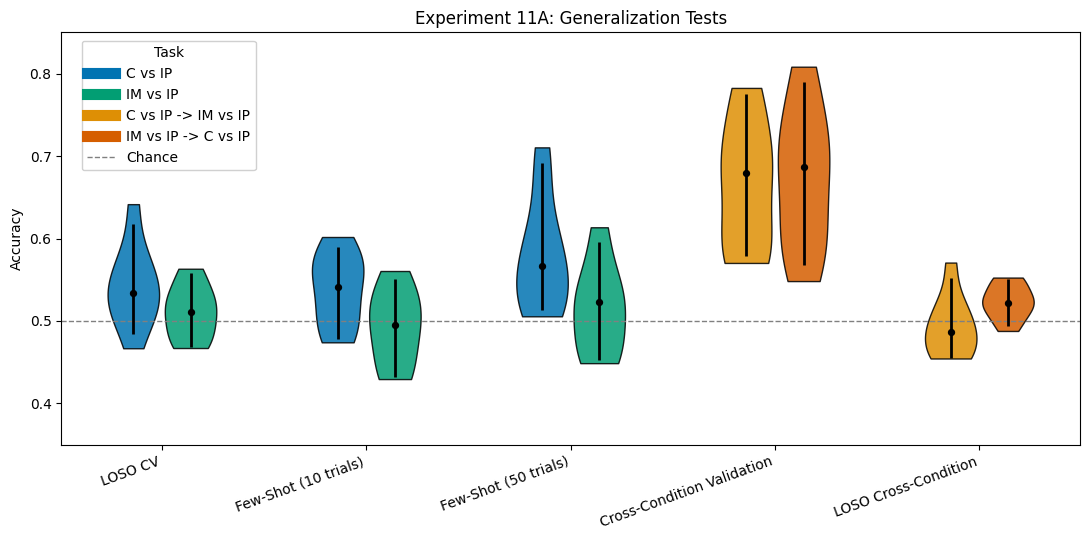


=== Subject-Identification Control Test (Experiment 11B) ===
Chance level: 0.1000
                  Method     mean      std
Riemann covariance + LDA 1.000000 0.000000
     STFT log-power + LR 0.980626 0.004218
Interpretation: this is a within-cohort subject-fingerprint control, not an unseen-subject test. Very high accuracy is plausible when train/test contain held-out trials from the same people.


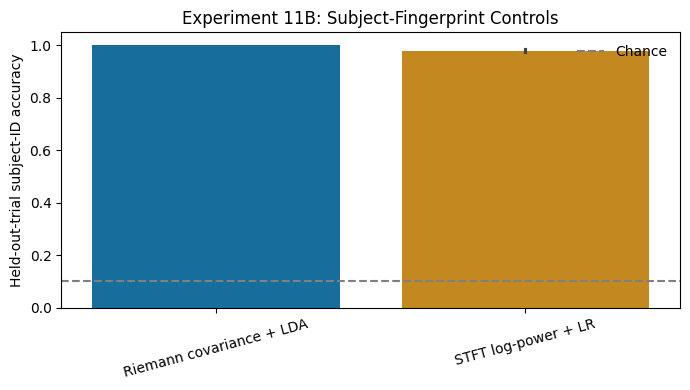

In [ ]:
exp11_gen_file = paths.tables_dir / "exp11_generalization_results.csv"
exp11_subject_file = paths.tables_dir / "exp11_subject_id_results.csv"


def exp11a_has_all_tests(df_gen):
    expected = {
        ("C vs IP", "LOSO CV"),
        ("C vs IP", "Few-Shot (10 trials)"),
        ("C vs IP", "Few-Shot (50 trials)"),
        ("IM vs IP", "LOSO CV"),
        ("IM vs IP", "Few-Shot (10 trials)"),
        ("IM vs IP", "Few-Shot (50 trials)"),
        ("C vs IP -> IM vs IP", "Cross-Condition Validation"),
        ("IM vs IP -> C vs IP", "Cross-Condition Validation"),
        ("C vs IP -> IM vs IP", "LOSO Cross-Condition"),
        ("IM vs IP -> C vs IP", "LOSO Cross-Condition"),
    }
    if df_gen.empty or not {"Task", "Test"}.issubset(df_gen.columns):
        return False
    observed = set(zip(df_gen["Task"], df_gen["Test"]))
    return expected.issubset(observed)


def plot_exp11a_generalization(df_gen):
    summary = df_gen.groupby(["Test", "Task"])["Accuracy"].mean().reset_index()
    print("\n=== Generalization Tests Summary (Experiment 11A) ===")
    print(summary.to_string(index=False))

    order = [
        "LOSO CV",
        "Few-Shot (10 trials)",
        "Few-Shot (50 trials)",
        "Cross-Condition Validation",
        "LOSO Cross-Condition",
    ]
    present_order = [test for test in order if test in set(df_gen["Test"])]
    fig, ax = plt.subplots(figsize=(11, 5.5))
    palette = dict(
        zip(sorted(df_gen["Task"].unique()), sns.color_palette("colorblind", n_colors=df_gen["Task"].nunique()))
    )
    width = 0.28
    legend_handles = {}

    for x_pos, test_name in enumerate(present_order):
        test_df = df_gen[df_gen["Test"] == test_name]
        task_names = list(test_df["Task"].drop_duplicates())
        offsets = np.linspace(-width * (len(task_names) - 1) / 2, width * (len(task_names) - 1) / 2, len(task_names))
        for offset, task_name in zip(offsets, task_names):
            values = test_df.loc[test_df["Task"] == task_name, "Accuracy"].dropna().to_numpy()
            if len(values) == 0:
                continue
            parts = ax.violinplot(
                values,
                positions=[x_pos + offset],
                widths=width * 0.9,
                showmeans=False,
                showmedians=False,
                showextrema=False,
            )
            for body in parts["bodies"]:
                body.set_facecolor(palette[task_name])
                body.set_edgecolor("black")
                body.set_alpha(0.85)
                body.set_linewidth(1)
            quartiles = np.percentile(values, [25, 50, 75])
            ax.scatter([x_pos + offset], [quartiles[1]], color="black", s=18, zorder=4)
            ax.vlines(x_pos + offset, quartiles[0], quartiles[2], color="black", linewidth=2, zorder=3)
            legend_handles.setdefault(task_name, plt.Line2D([0], [0], color=palette[task_name], lw=8))

    chance_line = ax.axhline(0.5, linestyle="--", color="gray", linewidth=1, label="Chance")
    ax.set_title("Experiment 11A: Generalization Tests")
    ax.set_ylabel("Accuracy")
    ax.set_xlabel("")
    ax.set_ylim(0.35, 0.85)
    ax.set_xticks(range(len(present_order)))
    ax.set_xticklabels(present_order, rotation=20, ha="right")
    ax.legend(
        list(legend_handles.values()) + [chance_line],
        list(legend_handles.keys()) + ["Chance"],
        title="Task",
        loc="upper left",
        bbox_to_anchor=(0.02, 0.98),
        frameon=True,
        framealpha=0.92,
        borderaxespad=0.0,
    )
    plt.tight_layout()
    plt.savefig(paths.figures_dir / "experiment11a_generalization_results.png", dpi=300)
    plt.show()


try:
    df_gen = pd.read_csv(exp11_gen_file)
    if not exp11a_has_all_tests(df_gen):
        raise FileNotFoundError("Cached Experiment 11A is missing the expanded generalization tests.")
    plot_exp11a_generalization(df_gen)
except FileNotFoundError:
    from sklearn.pipeline import make_pipeline
    from pyriemann.estimation import Covariances
    from pyriemann.tangentspace import TangentSpace
    from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
    from sklearn.metrics import accuracy_score
    import seaborn as sns

    print("Running Experiment 11A: Generalization Tests and Cross-Condition Validation")

    cluster_chans = TARGET_BANDS_CLUSTERS["theta"] + TARGET_BANDS_CLUSTERS["alpha"]

    task_data = {
        "C vs IP": {
            "X": X_subs_c,
            "y": y_subs_c,
            "dataset": dataset_c,
        },
        "IM vs IP": {
            "X": X_subs_im,
            "y": y_subs_im,
            "dataset": dataset_im,
        },
    }
    for task_cfg in task_data.values():
        ds = task_cfg["dataset"]
        task_cfg["picks"] = [ds.channel_names.index(ch) for ch in cluster_chans if ch in ds.channel_names]
        task_cfg["time_mask"] = (ds.times >= 0.375) & (ds.times <= 1.242)

    def make_exp11a_pipeline():
        return make_pipeline(
            Covariances(estimator="oas"), TangentSpace(metric="riemann"), LDA(solver="lsqr", shrinkage="auto")
        )

    def task_subject_arrays(task_label, subject):
        cfg = task_data[task_label]
        X = cfg["X"][subject][:, cfg["picks"]][..., cfg["time_mask"]]
        y = cfg["y"][subject]
        return X, y

    def concat_subjects(task_label, subjects):
        X_parts, y_parts = zip(*(task_subject_arrays(task_label, sub) for sub in subjects))
        return np.concatenate(X_parts, axis=0), np.concatenate(y_parts, axis=0)

    gen_results = []

    for task_label in ["C vs IP", "IM vs IP"]:
        for test_sub_idx, test_sub in enumerate(target_subjects):
            train_subs = [s for i, s in enumerate(target_subjects) if i != test_sub_idx]
            X_train_loso, y_train_loso = concat_subjects(task_label, train_subs)
            X_test_loso, y_test_loso = task_subject_arrays(task_label, test_sub)
            X_train_loso, X_test_loso = standardize_global_fold(X_train_loso, X_test_loso)
            pipeline = make_exp11a_pipeline()
            pipeline.fit(X_train_loso, y_train_loso)
            gen_results.append(
                {
                    "Subject": test_sub,
                    "Test": "LOSO CV",
                    "Accuracy": accuracy_score(y_test_loso, pipeline.predict(X_test_loso)),
                    "Task": task_label,
                }
            )

        for n_shots in [10, 50]:
            for test_sub_idx, test_sub in enumerate(target_subjects):
                train_subs = [s for i, s in enumerate(target_subjects) if i != test_sub_idx]
                X_train_loso, y_train_loso = concat_subjects(task_label, train_subs)
                X_test_loso, y_test_loso = task_subject_arrays(task_label, test_sub)
                X_adapt, X_eval = X_test_loso[:n_shots], X_test_loso[n_shots:]
                y_adapt, y_eval = y_test_loso[:n_shots], y_test_loso[n_shots:]
                if len(y_eval) == 0 or len(np.unique(y_adapt)) < 2:
                    continue
                X_train_all = np.concatenate([X_train_loso, X_adapt], axis=0)
                y_train_all = np.concatenate([y_train_loso, y_adapt], axis=0)
                X_train_all, X_eval = standardize_global_fold(X_train_all, X_eval)
                pipeline = make_exp11a_pipeline()
                pipeline.fit(X_train_all, y_train_all)
                gen_results.append(
                    {
                        "Subject": test_sub,
                        "Test": f"Few-Shot ({n_shots} trials)",
                        "Accuracy": accuracy_score(y_eval, pipeline.predict(X_eval)),
                        "Task": task_label,
                    }
                )

    for source_task, target_task in [("C vs IP", "IM vs IP"), ("IM vs IP", "C vs IP")]:
        transfer_label = f"{source_task} -> {target_task}"
        for sub in target_subjects:
            X_tr, y_tr = task_subject_arrays(source_task, sub)
            X_te, y_te = task_subject_arrays(target_task, sub)
            X_tr, X_te = standardize_global_fold(X_tr, X_te)
            pipeline = make_exp11a_pipeline()
            pipeline.fit(X_tr, y_tr)
            gen_results.append(
                {
                    "Subject": sub,
                    "Test": "Cross-Condition Validation",
                    "Accuracy": accuracy_score(y_te, pipeline.predict(X_te)),
                    "Task": transfer_label,
                }
            )

        for test_sub_idx, test_sub in enumerate(target_subjects):
            train_subs = [s for i, s in enumerate(target_subjects) if i != test_sub_idx]
            X_tr, y_tr = concat_subjects(source_task, train_subs)
            X_te, y_te = task_subject_arrays(target_task, test_sub)
            X_tr, X_te = standardize_global_fold(X_tr, X_te)
            pipeline = make_exp11a_pipeline()
            pipeline.fit(X_tr, y_tr)
            gen_results.append(
                {
                    "Subject": test_sub,
                    "Test": "LOSO Cross-Condition",
                    "Accuracy": accuracy_score(y_te, pipeline.predict(X_te)),
                    "Task": transfer_label,
                }
            )

    df_gen = pd.DataFrame(gen_results)
    df_gen.to_csv(exp11_gen_file, index=False)
    print("Experiment 11A generalization tests saved to cache.")
    plot_exp11a_generalization(df_gen)


def plot_exp11b_subject_id_control(df_sub):
    if "Method" not in df_sub.columns:
        df_sub = df_sub.copy()
        df_sub["Method"] = "Riemann covariance + LDA"
    chance_subject_id = 1 / len(target_subjects)
    summary = df_sub.groupby("Method")["Accuracy"].agg(["mean", "std"]).reset_index()
    print("\n=== Subject-Identification Control Test (Experiment 11B) ===")
    print(f"Chance level: {chance_subject_id:.4f}")
    print(summary.to_string(index=False))
    print(
        "Interpretation: this is a within-cohort subject-fingerprint control, not an unseen-subject test. "
        "Very high accuracy is plausible when train/test contain held-out trials from the same people."
    )

    plt.figure(figsize=(7, 4))
    ax = sns.barplot(data=df_sub, x="Method", y="Accuracy", palette="colorblind", errorbar="sd")
    ax.axhline(chance_subject_id, linestyle="--", color="gray", label="Chance")
    ax.set_ylim(0, 1.05)
    ax.set_title("Experiment 11B: Subject-Fingerprint Controls")
    ax.set_xlabel("")
    ax.set_ylabel("Held-out-trial subject-ID accuracy")
    ax.tick_params(axis="x", rotation=15)
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.savefig(paths.figures_dir / "experiment11b_subject_id_control.png", dpi=300)
    plt.show()


try:
    df_sub = pd.read_csv(exp11_subject_file)
    if "Method" not in df_sub.columns or df_sub["Method"].nunique() < 2:
        raise FileNotFoundError("Cached Experiment 11B is missing the two-method fingerprint controls.")
    plot_exp11b_subject_id_control(df_sub)
except FileNotFoundError:
    from sklearn.model_selection import StratifiedKFold
    from sklearn.metrics import accuracy_score
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression
    from scipy.signal import stft

    X_sub_all = []
    y_sub_all = []
    for idx, sub in enumerate(target_subjects):
        X_sub_all.append(X_subs_c[sub])
        y_sub_all.append(np.full(len(X_subs_c[sub]), idx))
    X_all_s = np.concatenate(X_sub_all, axis=0)
    y_all_s = np.concatenate(y_sub_all, axis=0)
    t_mask = (dataset_c.times >= 0.375) & (dataset_c.times <= 1.242)
    X_all_s = X_all_s[..., t_mask] * 1e6

    def stft_logpower_features(X, sfreq=128.0):
        _, _, Zxx = stft(
            X,
            fs=sfreq,
            axis=-1,
            nperseg=min(64, X.shape[-1]),
            noverlap=min(32, max(0, X.shape[-1] // 2)),
            boundary=None,
            padded=False,
        )
        power = np.log1p(np.abs(Zxx) ** 2)
        return power.reshape(power.shape[0], -1)

    # Within-cohort fingerprint test: each fold holds out trials, not subjects.
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    fold_results = []
    X_stft = stft_logpower_features(X_all_s, sfreq=128.0)
    for f_idx, (tr, te) in enumerate(skf.split(X_all_s, y_all_s)):
        riemann_pipeline = make_pipeline(
            Covariances(estimator="oas"), TangentSpace(metric="riemann"), LDA(solver="lsqr", shrinkage="auto")
        )
        riemann_pipeline.fit(X_all_s[tr], y_all_s[tr])
        riemann_acc = accuracy_score(y_all_s[te], riemann_pipeline.predict(X_all_s[te]))
        fold_results.append({"Fold": f_idx + 1, "Method": "Riemann covariance + LDA", "Accuracy": riemann_acc})

        stft_pipeline = make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=2000, C=1.0, solver="lbfgs"),
        )
        stft_pipeline.fit(X_stft[tr], y_all_s[tr])
        stft_acc = accuracy_score(y_all_s[te], stft_pipeline.predict(X_stft[te]))
        fold_results.append({"Fold": f_idx + 1, "Method": "STFT log-power + LR", "Accuracy": stft_acc})

    df_sub = pd.DataFrame(fold_results)
    df_sub.to_csv(exp11_subject_file, index=False)
    print("Experiment 11B subject-ID control saved to cache.")
    plot_exp11b_subject_id_control(df_sub)